# Simulazione Monte Carlo del rischio di portafoglio
### Value at Risk (VaR) ed Expected Shortfall (ES) su un portafoglio FTSE MIB

**Autore:** Luca Orlando — Università di Torino

---

**Come usare questo notebook**

Il notebook è diviso in blocchi. I blocchi di testo (come questo) spiegano; i blocchi di codice (con lo sfondo grigio) eseguono i calcoli.

- Per eseguire un blocco di codice: cliccaci sopra e premi il pulsante ▶ a sinistra (oppure `Shift + Invio`).
- Per eseguire tutto dall'inizio alla fine: menu **Runtime → Esegui tutto**.
- I blocchi vanno eseguiti **in ordine**, dall'alto verso il basso: ognuno usa i risultati dei precedenti.

**Domanda di ricerca.** Quanto pesa la struttura di correlazione tra i titoli, rispetto al rischio dei singoli titoli, nel determinare la perdita potenziale di un portafoglio azionario su un orizzonte di un mese?

## 0. Preparazione

Il primo blocco carica le librerie. `yfinance` scarica i prezzi da Yahoo Finance; `numpy` e `scipy` fanno i calcoli; `matplotlib` disegna i grafici.

In [1]:
!pip install -q yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import yfinance as yf

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.options.display.float_format = "{:.4f}".format
print("Librerie caricate.")

Librerie caricate.


### Configurazione

Tutte le scelte del progetto sono raccolte qui. Per cambiare titoli, pesi o orizzonte basta modificare questo blocco e rieseguire tutto.

- **Titoli:** due banche (Intesa, UniCredit), un'assicurazione (Generali), un'utility (Enel) e un'energetica (Eni). Le due banche sono molto correlate tra loro: è voluto, perché il progetto studia proprio l'effetto della correlazione.
- **Storico dal 2008:** serve per le estensioni successive (backtest e stress test sulle crisi). I parametri invece si stimano solo sugli ultimi 2 anni.
- **Orizzonte:** 21 giorni di borsa, cioè circa un mese.

In [2]:
TICKER  = ["ISP.MI", "UCG.MI", "ENEL.MI", "ENI.MI", "G.MI"]
NOMI    = ["Intesa Sanpaolo", "UniCredit", "Enel", "Eni", "Generali"]
PESI    = np.full(len(TICKER), 1 / len(TICKER))    # portafoglio equipesato (20% ciascuno)

INIZIO          = "2008-01-01"
ANNI_DI_STIMA   = 2          # finestra per stimare i parametri
ORIZZONTE       = 21         # giorni di borsa (~1 mese)
N_SIMULAZIONI   = 10_000
LIVELLI         = [0.95, 0.99]
VALORE_PORTAFOGLIO = 100_000  # euro, solo per esprimere le perdite in valore
MEDIA_ZERO      = True       # ipotesi principale mu = 0 (vedi Step 2); False = media stimata
SEED            = 42         # rende i risultati riproducibili

assert np.isclose(PESI.sum(), 1), "I pesi devono sommare a 1"

## Step 1 — Dati

Scarichiamo i **prezzi di chiusura rettificati**: sono corretti per dividendi, frazionamenti e aumenti di capitale, così che la variazione da un giorno all'altro rifletta il rendimento effettivo dell'azionista.

Calcoliamo due tipi di rendimento giornaliero:
- **logaritmico**, $r_t = \ln(P_t / P_{t-1})$: si somma nel tempo, quindi è comodo per aggregare sull'orizzonte di 21 giorni;
- **semplice**, $R_t = P_t / P_{t-1} - 1$: si combina tra titoli con i pesi del portafoglio.

Prima data disponibile per ciascun titolo:
Ticker
ISP.MI     2008-01-02
UCG.MI     2008-01-02
ENEL.MI    2008-01-02
ENI.MI     2008-01-02
G.MI       2008-01-02

Periodo analizzato: 2008-01-02 – 2026-11-06 (4789 giorni di borsa)


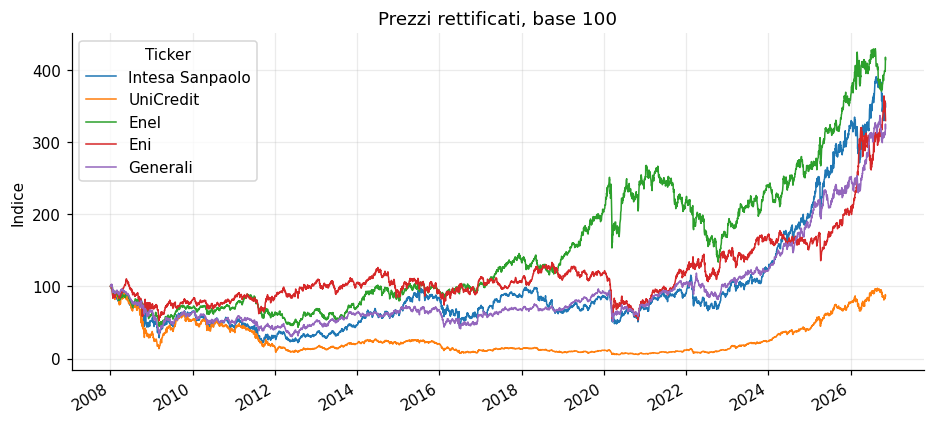

In [3]:
USA_DATI_SINTETICI = False   # lasciare False: True serve solo per collaudare il notebook senza internet

if not USA_DATI_SINTETICI:
    grezzi = yf.download(TICKER, start=INIZIO, auto_adjust=True, progress=False)
    prezzi = grezzi["Close"][TICKER]
else:
    _rng = np.random.default_rng(7)
    _mu, _sig = np.array([.08, .10, .06, .05, .07]), np.array([.30, .38, .22, .26, .23])
    _c = np.array([[1, .88, .45, .5, .7], [.88, 1, .42, .5, .68], [.45, .42, 1, .4, .5],
                   [.5, .5, .4, 1, .48], [.7, .68, .5, .48, 1]])
    _L = np.linalg.cholesky(np.outer(_sig, _sig) * _c / 252)
    _r = _mu / 252 + _rng.standard_normal((252 * 6, 5)) @ _L.T
    prezzi = pd.DataFrame(100 * np.exp(_r.cumsum(0)), columns=TICKER,
                          index=pd.bdate_range("2019-01-01", periods=252 * 6))

print("Prima data disponibile per ciascun titolo:")
print(prezzi.apply(lambda s: s.first_valid_index().date()).to_string())

prezzi = prezzi.dropna()          # teniamo solo i giorni in cui tutti i titoli hanno un prezzo
rend_log = np.log(prezzi).diff().dropna()
rend_semplici = prezzi.pct_change().dropna()

print(f"\nPeriodo analizzato: {prezzi.index[0].date()} – {prezzi.index[-1].date()} "
      f"({len(prezzi)} giorni di borsa)")

(prezzi / prezzi.iloc[0] * 100).rename(columns=dict(zip(TICKER, NOMI))).plot(figsize=(10, 4.5), lw=1)
plt.title("Prezzi rettificati, base 100"); plt.ylabel("Indice"); plt.xlabel("")
plt.show()

### Controllo di qualità dei dati

Le banche italiane hanno fatto negli anni aumenti di capitale e raggruppamenti di azioni (UniCredit più volte tra il 2011 e il 2017). Se la rettifica di Yahoo è sbagliata, nei dati compare un rendimento giornaliero enorme che non è mai avvenuto.

Il blocco seguente elenca i rendimenti giornalieri oltre ±25%. Ognuno va **verificato a mano** su una seconda fonte (ad esempio il sito di Borsa Italiana o le notizie del giorno): se è un errore, va corretto prima di proseguire.

In [4]:
SOGLIA = 0.25
anomalie = rend_semplici.stack()
anomalie = anomalie[anomalie.abs() > SOGLIA].rename("rendimento").reset_index()
anomalie.columns = ["data", "ticker", "rendimento"]

if anomalie.empty:
    print(f"Nessun rendimento giornaliero oltre ±{SOGLIA:.0%}.")
else:
    print(f"{len(anomalie)} rendimenti da verificare:")
    display(anomalie.style.format({"rendimento": "{:.2%}"}))

# I 10 giorni più estremi: devono corrispondere a eventi di mercato noti
# (es. ottobre 2008, Brexit 24/06/2016, marzo 2020). Una data senza spiegazione
# è probabilmente un errore di rettifica.
estremi = rend_semplici.stack().rename("rendimento").reset_index()
estremi.columns = ["data", "ticker", "rendimento"]
estremi = estremi.reindex(estremi["rendimento"].abs().sort_values(ascending=False).index).head(10)
print("\nI 10 rendimenti giornalieri più estremi del campione:")
display(estremi.reset_index(drop=True).style.format({"rendimento": "{:.2%}", "data": lambda d: d.date()}))

Nessun rendimento giornaliero oltre ±25%.

I 10 rendimenti giornalieri più estremi del campione:


,data,ticker,rendimento
0,2016-06-24,UCG.MI,-23.79%
1,2016-06-24,ISP.MI,-22.94%
2,2010-05-10,UCG.MI,20.93%
3,2020-03-09,ENI.MI,-20.85%
4,2020-03-12,ENEL.MI,-19.85%
5,2010-05-10,ISP.MI,19.68%
6,2008-11-04,UCG.MI,19.18%
7,2009-03-18,UCG.MI,19.05%
8,2008-10-13,ENEL.MI,18.37%
9,2020-03-12,ENI.MI,-18.11%


## Step 2 — Stima dei parametri

Sugli ultimi 2 anni stimiamo, per ogni titolo, il **rendimento medio** e la **volatilità**, e tra i titoli la **matrice di correlazione**. Sono gli input della simulazione.

I calcoli sono giornalieri; la versione annualizzata ($\mu \times 252$, $\sigma \times \sqrt{252}$) serve solo per leggere più facilmente i numeri.

**Attenzione all'errore standard della media.** Con due anni di dati, l'errore standard del rendimento medio è spesso grande quanto il rendimento stesso: la media è stimata in modo molto impreciso. Per questo nella pratica del risk management si usa spesso l'ipotesi $\mu = 0$ (opzione `MEDIA_ZERO` nella configurazione).

Finestra di stima: 2024-11-07 – 2026-11-06 (505 osservazioni)


,Rendimento medio annuo,Errore standard,Volatilità annua
Intesa Sanpaolo,29.36%,17.88%,25.31%
UniCredit,36.85%,22.54%,31.91%
Enel,23.26%,13.51%,19.12%
Eni,35.12%,17.29%,24.47%
Generali,31.44%,13.71%,19.40%


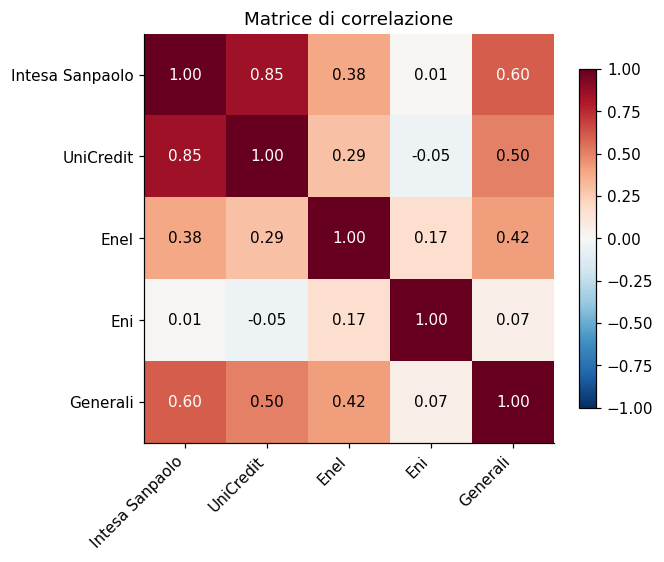

In [5]:
inizio_stima = rend_log.index[-1] - pd.DateOffset(years=ANNI_DI_STIMA)
finestra = rend_log[rend_log.index > inizio_stima]

mu_g    = finestra.mean().to_numpy()                 # media giornaliera
cov_g   = finestra.cov().to_numpy()                  # covarianza giornaliera
sigma_g = np.sqrt(np.diag(cov_g))                    # volatilità giornaliera
corr    = cov_g / np.outer(sigma_g, sigma_g)

parametri = pd.DataFrame({
    "Rendimento medio annuo": mu_g * 252,
    "Errore standard":        sigma_g / np.sqrt(len(finestra)) * 252,
    "Volatilità annua":       sigma_g * np.sqrt(252),
}, index=NOMI)

print(f"Finestra di stima: {finestra.index[0].date()} – {finestra.index[-1].date()} "
      f"({len(finestra)} osservazioni)")
display(parametri.style.format("{:.2%}"))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NOMI)), NOMI, rotation=45, ha="right"); ax.set_yticks(range(len(NOMI)), NOMI)
ax.grid(False)
for i in range(len(NOMI)):
    for j in range(len(NOMI)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr[i, j]) > 0.6 else "black")
fig.colorbar(im, shrink=0.8); ax.set_title("Matrice di correlazione")
plt.show()

## Step 3 — Simulazione Monte Carlo

**Il modello.** Ipotizziamo che i log-rendimenti giornalieri siano normali, con media $\mu$ e covarianza $\Sigma$, e indipendenti da un giorno all'altro. Allora il log-rendimento cumulato su $h = 21$ giorni è anch'esso normale:

$$R_h \sim N(h\mu,\; h\Sigma)$$

**Il ruolo di Cholesky.** Il computer sa generare numeri casuali normali *indipendenti*, $z \sim N(0, I)$. Per renderli *correlati* come i titoli reali scomponiamo la matrice di covarianza come $\Sigma = L L^\top$ (decomposizione di Cholesky, $L$ è triangolare inferiore). Il vettore $L z$ ha esattamente covarianza $\Sigma$:

$$R_h = h\mu + \sqrt{h}\, L z$$

Senza questo passaggio i titoli verrebbero simulati come indipendenti e il rischio del portafoglio risulterebbe gravemente sottostimato (lo misuriamo più sotto).

**Dal titolo al portafoglio.** I pesi si applicano ai rendimenti *semplici*, non ai logaritmici. Per questo convertiamo ($e^{R} - 1$) prima di fare la media ponderata: è la cosiddetta *rivalutazione piena*.

In [6]:
def simula_titoli(mu, cov, orizzonte, n, seed, correlati=True):
    # Log-rendimenti cumulati sull'orizzonte: matrice (n scenari x n titoli).
    rng = np.random.default_rng(seed)
    matrice = cov if correlati else np.diag(np.diag(cov))   # correlati=False: solo varianze
    L = np.linalg.cholesky(matrice)                         # Sigma = L L'
    z = rng.standard_normal((n, len(mu)))                   # normali indipendenti
    return orizzonte * mu + np.sqrt(orizzonte) * z @ L.T

def rendimento_portafoglio(log_rend, pesi, rivalutazione="piena"):
    if rivalutazione == "piena":
        return np.expm1(log_rend) @ pesi      # w' (e^R - 1): esatto
    return log_rend @ pesi                    # w' R: approssimazione lineare (normale)

mu_sim = np.zeros_like(mu_g) if MEDIA_ZERO else mu_g
scenari_titoli = simula_titoli(mu_sim, cov_g, ORIZZONTE, N_SIMULAZIONI, SEED)
rp = rendimento_portafoglio(scenari_titoli, PESI)

# Controllo: la correlazione degli scenari simulati deve riprodurre quella stimata
scarto = np.abs(np.corrcoef(scenari_titoli, rowvar=False) - corr).max()
print(f"Scenari generati: {N_SIMULAZIONI:,}")
print(f"Scarto massimo fra correlazione simulata e stimata: {scarto:.3f}  (atteso: circa 0,01-0,02)")

Scenari generati: 10,000
Scarto massimo fra correlazione simulata e stimata: 0.015  (atteso: circa 0,01-0,02)


## Step 4 — VaR ed Expected Shortfall

Ordiniamo i 10.000 rendimenti simulati dal peggiore al migliore. Al livello di confidenza del 95% consideriamo il 5% peggiore, cioè i 500 scenari peggiori:

- **VaR 95%**: la perdita del 500° scenario peggiore. *"Nel 95% dei mesi la perdita non supera questo valore."*
- **ES 95%**: la perdita media dei 500 scenari peggiori. *"Nei mesi che vanno peggio del VaR, in media si perde questo."*

Il VaR dice dove inizia la coda; l'ES dice quanto è profonda. Per questo la regolamentazione bancaria (Basilea, FRTB) è passata dal VaR all'ES.

**Intervallo di confidenza.** Con un numero finito di scenari il VaR stimato oscilla un po'. Ricampionando gli scenari (*bootstrap*) misuriamo questa incertezza.

Perdite potenziali a 21 giorni su un portafoglio di 100,000 €


,VaR,VaR (€),IC 95% VaR,ES,ES (€),IC 95% ES
Livello,,,,,,
95%,7.45%,"7,449","[7.24%, 7.58%]",9.13%,"9,131","[8.95%, 9.32%]"
99%,10.17%,"10,165","[9.92%, 10.43%]",11.40%,"11,400","[11.08%, 11.72%]"


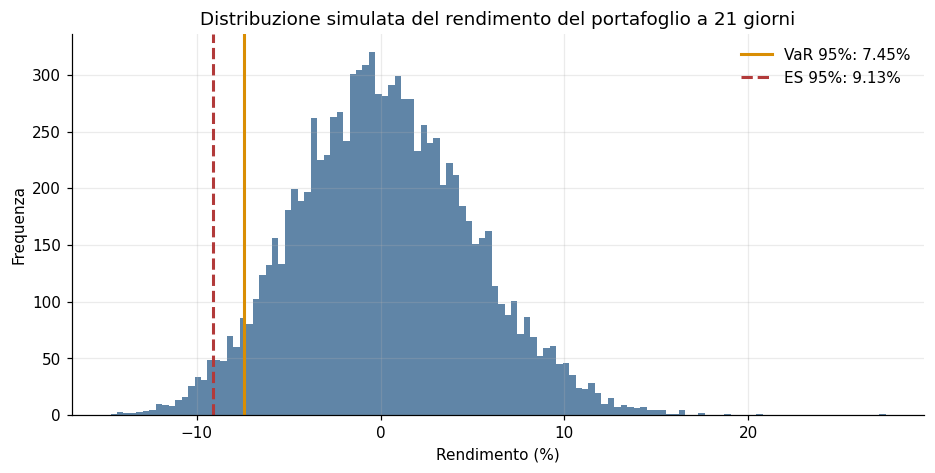

In [7]:
def var_es(rendimenti, alpha):
    r = np.sort(rendimenti)                                  # dal peggiore al migliore
    k = max(1, int(np.ceil(round(len(r) * (1 - alpha), 9))))  # n. di scenari nella coda
    return -r[k - 1], -r[:k].mean()                          # perdite espresse come numeri positivi

def intervallo_bootstrap(rendimenti, alpha, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    stime = np.array([var_es(rendimenti[rng.integers(0, len(rendimenti), len(rendimenti))], alpha)
                      for _ in range(n_boot)])
    return np.quantile(stime, [0.025, 0.975], axis=0)        # righe: [2,5%, 97,5%]; colonne: [VaR, ES]

righe = []
for a in LIVELLI:
    v, e = var_es(rp, a)
    ic = intervallo_bootstrap(rp, a)
    righe.append({"Livello": f"{a:.0%}", "VaR": v, "VaR (€)": v * VALORE_PORTAFOGLIO,
                  "IC 95% VaR": f"[{ic[0,0]:.2%}, {ic[1,0]:.2%}]",
                  "ES": e, "ES (€)": e * VALORE_PORTAFOGLIO,
                  "IC 95% ES": f"[{ic[0,1]:.2%}, {ic[1,1]:.2%}]"})
risultati = pd.DataFrame(righe).set_index("Livello")
print(f"Perdite potenziali a {ORIZZONTE} giorni su un portafoglio di {VALORE_PORTAFOGLIO:,.0f} €")
display(risultati.style.format({"VaR": "{:.2%}", "ES": "{:.2%}", "VaR (€)": "{:,.0f}", "ES (€)": "{:,.0f}"}))

v95, e95 = var_es(rp, 0.95)
plt.figure(figsize=(10, 4.5))
plt.hist(rp * 100, bins=120, color="#2B5C8A", alpha=0.75)
plt.axvline(-v95 * 100, color="#D98E04", lw=2, label=f"VaR 95%: {v95:.2%}")
plt.axvline(-e95 * 100, color="#B23A3A", lw=2, ls="--", label=f"ES 95%: {e95:.2%}")
plt.title(f"Distribuzione simulata del rendimento del portafoglio a {ORIZZONTE} giorni")
plt.xlabel("Rendimento (%)"); plt.ylabel("Frequenza"); plt.legend(frameon=False)
plt.show()

## Verifiche di correttezza

Un risultato numerico vale qualcosa solo se si può dimostrare che il codice è corretto. Facciamo tre confronti.

**1. Forma chiusa.** Se usiamo la rivalutazione lineare ($w^\top R$), il rendimento del portafoglio è esattamente normale, con $\mu_p = h\,w^\top\mu$ e $\sigma_p = \sqrt{h\,w^\top \Sigma w}$. In questo caso VaR ed ES hanno una formula esatta:

$$\text{VaR} = -(\mu_p + \sigma_p z), \qquad \text{ES} = -\mu_p + \sigma_p\,\frac{\varphi(z)}{1-\alpha}, \qquad z = \Phi^{-1}(1-\alpha)$$

Il Monte Carlo lineare deve dare lo stesso risultato, a meno dell'errore di simulazione.

**2. Rivalutazione piena vs lineare.** Misura quanto conta convertire correttamente i log-rendimenti.

**3. Senza correlazione.** Ripetiamo la simulazione saltando Cholesky (titoli indipendenti): misura l'errore che si commetterebbe ignorando la correlazione.

In [8]:
mu_p    = ORIZZONTE * PESI @ mu_sim
sigma_p = np.sqrt(ORIZZONTE * PESI @ cov_g @ PESI)

rp_lineare   = rendimento_portafoglio(scenari_titoli, PESI, rivalutazione="lineare")
rp_senza_corr = rendimento_portafoglio(simula_titoli(mu_sim, cov_g, ORIZZONTE, N_SIMULAZIONI, SEED,
                                                     correlati=False), PESI)
confronto = []
for a in LIVELLI:
    z = norm.ppf(1 - a)
    confronto += [
        {"Livello": f"{a:.0%}", "Metodo": "Formula chiusa (lineare)",
         "VaR": -(mu_p + sigma_p * z), "ES": -mu_p + sigma_p * norm.pdf(z) / (1 - a)},
        {"Livello": f"{a:.0%}", "Metodo": "Monte Carlo lineare", **dict(zip(["VaR", "ES"], var_es(rp_lineare, a)))},
        {"Livello": f"{a:.0%}", "Metodo": "Monte Carlo, rivalutazione piena", **dict(zip(["VaR", "ES"], var_es(rp, a)))},
        {"Livello": f"{a:.0%}", "Metodo": "Monte Carlo SENZA correlazione (errato)",
         **dict(zip(["VaR", "ES"], var_es(rp_senza_corr, a)))},
    ]
display(pd.DataFrame(confronto).set_index(["Livello", "Metodo"]).style.format("{:.2%}"))

### Convergenza: quanti scenari servono?

Ripetiamo la simulazione 200 volte per diversi numeri di scenari e osserviamo quanto oscilla il VaR. La linea rossa è il valore esatto della formula chiusa. Più scenari si usano, più la banda si stringe attorno al valore vero: l'errore si riduce come $1/\sqrt{n}$.

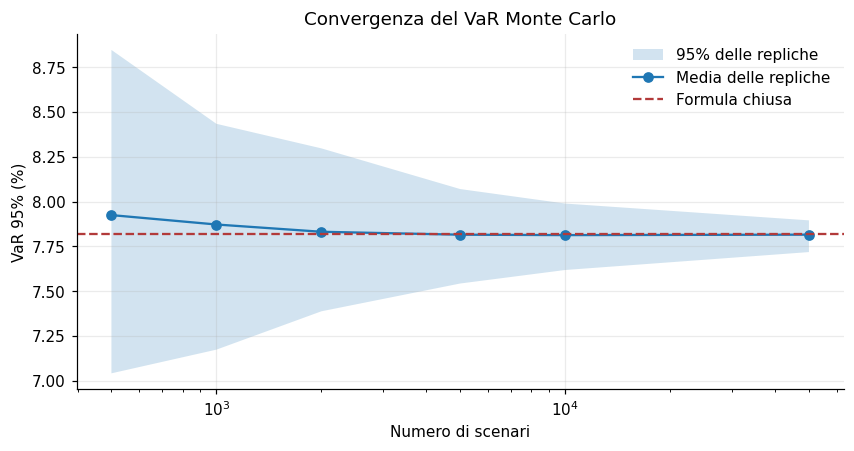

In [9]:
numeri = [500, 1_000, 2_000, 5_000, 10_000, 50_000]
var_esatto = -(mu_p + sigma_p * norm.ppf(0.05))
medie, basso, alto = [], [], []
for n in numeri:
    stime = [var_es(rendimento_portafoglio(simula_titoli(mu_sim, cov_g, ORIZZONTE, n, 1000 + k),
                                           PESI, "lineare"), 0.95)[0] for k in range(200)]
    medie.append(np.mean(stime)); basso.append(np.quantile(stime, .025)); alto.append(np.quantile(stime, .975))

plt.figure(figsize=(9, 4.2))
plt.fill_between(numeri, np.array(basso) * 100, np.array(alto) * 100, alpha=0.2, label="95% delle repliche")
plt.plot(numeri, np.array(medie) * 100, "o-", label="Media delle repliche")
plt.axhline(var_esatto * 100, color="#B23A3A", ls="--", label="Formula chiusa")
plt.xscale("log"); plt.xlabel("Numero di scenari"); plt.ylabel("VaR 95% (%)")
plt.title("Convergenza del VaR Monte Carlo"); plt.legend(frameon=False)
plt.show()

## Il beneficio della diversificazione

Confrontiamo il VaR di ciascun titolo preso da solo con il VaR del portafoglio. Se i titoli fossero perfettamente correlati, il VaR del portafoglio sarebbe la media ponderata dei VaR individuali; la differenza è il beneficio della diversificazione.

Il **rapporto di diversificazione** (somma pesata dei VaR individuali diviso VaR di portafoglio) vale 1 senza alcun beneficio e cresce quanto più la diversificazione funziona. Nello Step 5 vedremo come questo rapporto crolla quando le correlazioni salgono.

In [10]:
var_titoli = np.array([var_es(np.expm1(scenari_titoli[:, i]), 0.95)[0] for i in range(len(TICKER))])
tabella = pd.DataFrame({"VaR 95% da solo": var_titoli, "Peso": PESI}, index=NOMI)
display(tabella.style.format("{:.2%}"))

somma_pesata = PESI @ var_titoli
print(f"Media ponderata dei VaR individuali: {somma_pesata:.2%}")
print(f"VaR del portafoglio:                 {v95:.2%}")
print(f"Rapporto di diversificazione:        {somma_pesata / v95:.2f}")

,VaR 95% da solo,Peso
Intesa Sanpaolo,11.36%,20.00%
UniCredit,14.32%,20.00%
Enel,8.57%,20.00%
Eni,11.10%,20.00%
Generali,8.85%,20.00%


Media ponderata dei VaR individuali: 10.84%
VaR del portafoglio:                 7.45%
Rapporto di diversificazione:        1.46


## Step 5 — Sensibilità del rischio alla correlazione

Finora abbiamo usato la correlazione stimata sugli ultimi due anni. Ora chiediamo: **che cosa succede al rischio del portafoglio se le correlazioni cambiano**, e in particolare se salgono come accade nelle crisi?

**Come modificare le correlazioni senza "rompere" la matrice.** Non si possono alzare i coefficienti a caso: la matrice smetterebbe di essere una correlazione valida e la decomposizione di Cholesky fallirebbe. Usiamo invece una combinazione fra la matrice stimata $\hat\rho$ e due casi estremi, entrambi validi:

$$\rho(t) = \begin{cases} (1+t)\,\hat\rho + (-t)\,I & -1 \le t < 0 \quad \text{(verso l'indipendenza, } I\text{)} \\ (1-t)\,\hat\rho + t\,J & \;\;\,0 \le t \le 1 \quad \text{(verso la correlazione perfetta, } J\text{ = matrice di 1)} \end{cases}$$

Una combinazione di matrici valide è sempre valida. Con $t = -1$ i titoli sono indipendenti, con $t = 0$ si torna alla stima, con $t = 1$ si muovono tutti insieme.

**Stessi numeri casuali per ogni livello.** In ogni scenario di correlazione riutilizziamo le stesse estrazioni casuali $z$: così le differenze nel VaR dipendono solo dalla correlazione e non dal caso (tecnica dei *common random numbers*).

Le volatilità dei singoli titoli restano quelle stimate: cambia solo la correlazione.

In [11]:
def matrice_correlazione(rho, t):
    n = len(rho)
    if t < 0:
        return (1 + t) * rho + (-t) * np.eye(n)      # verso l'indipendenza
    return (1 - t) * rho + t * np.ones((n, n))       # verso la correlazione perfetta

def correlazione_media(rho):
    n = len(rho)
    return (rho.sum() - n) / (n * (n - 1))           # media dei coefficienti fuori diagonale

def simula_con_correlazione(rho, z, sigma=sigma_g):
    # Scenari a ORIZZONTE giorni con volatilità 'sigma' e correlazione 'rho', usando le estrazioni z.
    if np.allclose(rho, 1):                           # correlazione perfetta: un solo fattore comune
        return ORIZZONTE * mu_sim + np.sqrt(ORIZZONTE) * np.outer(z[:, 0], sigma)
    L = np.linalg.cholesky(np.diag(sigma) @ rho @ np.diag(sigma))
    return ORIZZONTE * mu_sim + np.sqrt(ORIZZONTE) * z @ L.T

z_comuni = np.random.default_rng(SEED).standard_normal((N_SIMULAZIONI, len(TICKER)))

griglia = [-1, -0.75, -0.5, -0.25, 0, 0.2, 0.4, 0.6, 0.8, 0.9, 1]
righe = []
for t in griglia:
    rho_t = matrice_correlazione(corr, t)
    scen = simula_con_correlazione(rho_t, z_comuni)
    r_t = rendimento_portafoglio(scen, PESI)
    v95, e95 = var_es(r_t, 0.95)
    v99, e99 = var_es(r_t, 0.99)
    var_singoli = np.array([var_es(np.expm1(scen[:, i]), 0.95)[0] for i in range(len(TICKER))])
    righe.append({"t": t, "Correlazione media": correlazione_media(rho_t),
                  "VaR 95%": v95, "ES 95%": e95, "VaR 99%": v99, "ES 99%": e99,
                  "Rapporto di diversificazione": PESI @ var_singoli / v95})
sensibilita = pd.DataFrame(righe).set_index("t")
base = sensibilita.loc[0, "VaR 95%"]
sensibilita["VaR 95% vs stima"] = sensibilita["VaR 95%"] / base - 1

display(sensibilita.style.format_index("{:+.2f}").format({"Correlazione media": "{:.2f}", "VaR 95%": "{:.2%}", "ES 95%": "{:.2%}",
                                  "VaR 99%": "{:.2%}", "ES 99%": "{:.2%}",
                                  "Rapporto di diversificazione": "{:.2f}", "VaR 95% vs stima": "{:+.1%}"}))

,Correlazione media,VaR 95%,ES 95%,VaR 99%,ES 99%,Rapporto di diversificazione,VaR 95% vs stima
t,,,,,,,
-1.00,0.00,4.86%,6.11%,6.94%,7.74%,2.22,-34.7%
-0.75,0.08,5.59%,7.00%,7.99%,8.82%,1.93,-25.0%
-0.50,0.16,6.27%,7.79%,8.83%,9.74%,1.73,-15.8%
-0.25,0.24,6.92%,8.49%,9.54%,10.60%,1.57,-7.0%
+0.00,0.32,7.45%,9.13%,10.17%,11.40%,1.46,+0.0%
+0.20,0.46,8.23%,10.11%,11.24%,12.65%,1.32,+10.4%
+0.40,0.59,9.01%,11.00%,12.16%,13.81%,1.20,+21.0%
+0.60,0.73,9.70%,11.82%,13.11%,14.89%,1.12,+30.2%
+0.80,0.86,10.27%,12.58%,13.99%,15.93%,1.05,+37.8%


### Dove si collocano le crisi reali?

Per dare un significato concreto alla curva, misuriamo la correlazione media e la volatilità dei titoli in alcune crisi storiche presenti nei dati. Se la serie storica non copre una crisi, quella crisi viene saltata.

In [12]:
CRISI = {
    "Crisi finanziaria (set 2008 – mar 2009)": ("2008-09-01", "2009-03-31"),
    "Debito sovrano (lug – dic 2011)":         ("2011-07-01", "2011-12-31"),
    "Covid (feb – apr 2020)":                  ("2020-02-20", "2020-04-30"),
    "Rialzo dei tassi (2022)":                 ("2022-01-01", "2022-12-31"),
}
righe_crisi = [{"Periodo": "Finestra di stima (ultimi 2 anni)",
                "Correlazione media": correlazione_media(corr),
                "Volatilità media annua": (sigma_g * np.sqrt(252)).mean()}]
parametri_crisi = {}
for nome, (da, a) in CRISI.items():
    f = rend_log.loc[da:a]
    if len(f) < 20:
        continue                                      # crisi non coperta dai dati
    rho_c = f.corr().to_numpy()
    sig_c = f.std().to_numpy()
    parametri_crisi[nome] = (rho_c, sig_c)
    righe_crisi.append({"Periodo": nome, "Correlazione media": correlazione_media(rho_c),
                        "Volatilità media annua": (sig_c * np.sqrt(252)).mean()})
crisi = pd.DataFrame(righe_crisi).set_index("Periodo")
display(crisi.style.format({"Correlazione media": "{:.2f}", "Volatilità media annua": "{:.1%}"}))

,Correlazione media,Volatilità media annua
Periodo,,
Finestra di stima (ultimi 2 anni),0.32,24.0%
Crisi finanziaria (set 2008 – mar 2009),0.67,72.3%
Debito sovrano (lug – dic 2011),0.78,56.3%
Covid (feb – apr 2020),0.80,78.2%
Rialzo dei tassi (2022),0.57,34.3%


### Il grafico

I punti sono i risultati Monte Carlo; la linea sottile è la formula chiusa gaussiana (lineare), calcolata su una griglia fine. Le linee verticali indicano la correlazione media osservata nelle crisi.

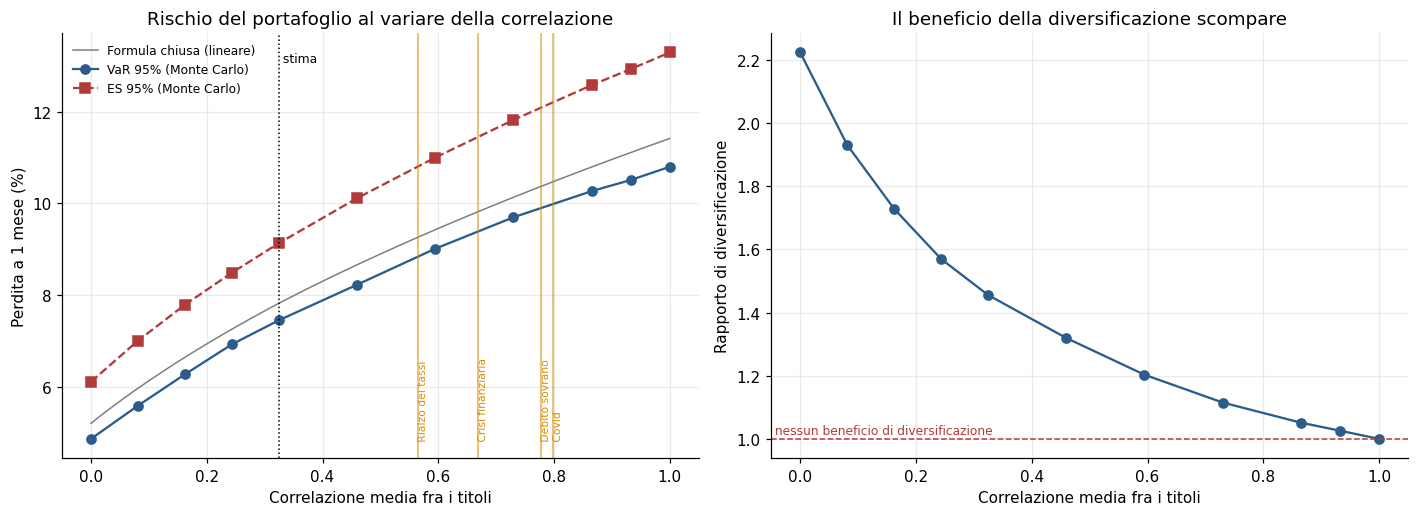

In [13]:
t_fine = np.linspace(-1, 1, 201)
x_fine = [correlazione_media(matrice_correlazione(corr, t)) for t in t_fine]
var_fine = []
for t in t_fine:
    cov_t = np.diag(sigma_g) @ matrice_correlazione(corr, t) @ np.diag(sigma_g)
    sp = np.sqrt(ORIZZONTE * PESI @ cov_t @ PESI)
    var_fine.append(-(ORIZZONTE * PESI @ mu_sim + sp * norm.ppf(0.05)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(x_fine, np.array(var_fine) * 100, color="#7F7F7F", lw=1, label="Formula chiusa (lineare)")
ax1.plot(sensibilita["Correlazione media"], sensibilita["VaR 95%"] * 100, "o-", color="#2B5C8A", label="VaR 95% (Monte Carlo)")
ax1.plot(sensibilita["Correlazione media"], sensibilita["ES 95%"] * 100, "s--", color="#B23A3A", label="ES 95% (Monte Carlo)")
ax1.axvline(correlazione_media(corr), color="black", lw=1, ls=":")
ax1.text(correlazione_media(corr), ax1.get_ylim()[1] * 0.97, " stima", va="top", fontsize=8)
for nome, (rho_c, _) in parametri_crisi.items():
    xc = correlazione_media(rho_c)
    ax1.axvline(xc, color="#D98E04", lw=1, alpha=0.7)
    ax1.text(xc, ax1.get_ylim()[0] + 0.3, " " + nome.split(" (")[0], rotation=90, va="bottom", fontsize=7, color="#D98E04")
ax1.set_xlabel("Correlazione media fra i titoli"); ax1.set_ylabel("Perdita a 1 mese (%)")
ax1.set_title("Rischio del portafoglio al variare della correlazione"); ax1.legend(frameon=False, fontsize=8)

ax2.plot(sensibilita["Correlazione media"], sensibilita["Rapporto di diversificazione"], "o-", color="#2B5C8A")
ax2.axhline(1, color="#B23A3A", ls="--", lw=1)
ax2.text(ax2.get_xlim()[0], 1.005, " nessun beneficio di diversificazione", fontsize=8, color="#B23A3A", va="bottom")
ax2.set_xlabel("Correlazione media fra i titoli"); ax2.set_ylabel("Rapporto di diversificazione")
ax2.set_title("Il beneficio della diversificazione scompare")
plt.tight_layout(); plt.show()

### Correlazione e volatilità insieme: il vero meccanismo delle crisi

Nelle crisi non sale solo la correlazione: sale anche la volatilità dei singoli titoli. Separiamo i due effetti applicando al portafoglio di oggi, per ciascuna crisi:

1. solo la **correlazione** della crisi (volatilità attuali);
2. solo la **volatilità** della crisi (correlazione attuale);
3. **entrambe**.

Se l'effetto combinato supera la somma dei due effetti separati, abbiamo trovato la non linearità: i due fattori si **moltiplicano**, non si sommano.

In [14]:
def var95(rho, sigma):
    return var_es(rendimento_portafoglio(simula_con_correlazione(rho, z_comuni, sigma), PESI), 0.95)[0]

righe_stress = []
for nome, (rho_c, sig_c) in parametri_crisi.items():
    solo_corr = var95(rho_c, sigma_g)
    solo_vol  = var95(corr, sig_c)
    entrambe  = var95(rho_c, sig_c)
    righe_stress.append({
        "Crisi": nome, "VaR 95% oggi": base,
        "Solo correlazione": solo_corr, "Solo volatilità": solo_vol, "Entrambe": entrambe,
        "Somma dei due effetti": (solo_corr - base) + (solo_vol - base),
        "Effetto combinato": entrambe - base,
    })
stress = pd.DataFrame(righe_stress).set_index("Crisi")
stress["Interazione"] = stress["Effetto combinato"] - stress["Somma dei due effetti"]
display(stress.style.format("{:.2%}"))

,VaR 95% oggi,Solo correlazione,Solo volatilità,Entrambe,Somma dei due effetti,Effetto combinato,Interazione
Crisi,,,,,,,
Crisi finanziaria (set 2008 – mar 2009),7.45%,9.37%,20.05%,25.17%,14.53%,17.72%,3.19%
Debito sovrano (lug – dic 2011),7.45%,9.82%,17.04%,21.19%,11.96%,13.74%,1.79%
Covid (feb – apr 2020),7.45%,10.01%,20.77%,28.73%,15.88%,21.28%,5.40%
Rialzo dei tassi (2022),7.45%,8.81%,10.50%,12.38%,4.41%,4.93%,0.52%


### Come leggere i risultati

**1. La forma della curva.** Nel modello gaussiano la varianza del portafoglio è *lineare* nella correlazione, quindi la volatilità (e il VaR) ne è la radice quadrata: la curva cresce ma con pendenza decrescente (è *concava*). La correlazione da sola, quindi, **non** fa esplodere il rischio. I punti Monte Carlo seguono la stessa forma della linea grigia della formula chiusa; stanno un po' più in basso perché il Monte Carlo usa la rivalutazione piena, che attenua le perdite (lo abbiamo visto nelle verifiche). Ciò che conta qui è la forma, non il livello.

**2. La diversificazione scompare.** Con correlazione perfetta il rapporto di diversificazione vale esattamente 1: il VaR del portafoglio diventa la media ponderata dei VaR dei singoli titoli. Diversificare non serve più a nulla, proprio quando servirebbe di più.

**3. Dove sta davvero la non linearità.** Nelle crisi correlazione e volatilità salgono *insieme*. Quando entrambi aumentano rispetto a oggi, l'effetto combinato supera la somma dei due effetti separati (colonna *Interazione* positiva): il rischio cresce più che proporzionalmente perché i due fattori si moltiplicano. In formula, se la volatilità del portafoglio cresce di un fattore $k$ per la volatilità e di un fattore $m$ per la correlazione, l'effetto combinato è $km - 1 = (k-1) + (m-1) + (k-1)(m-1)$: l'ultimo termine è l'interazione.

**4. Cosa il modello ancora non cattura.** Anche così, il modello gaussiano tratta le code in modo simmetrico e "sottile": nella realtà i titoli tendono a crollare insieme più spesso di quanto la sola correlazione lineare preveda (*dipendenza nelle code*). È il tema della prossima estensione (t di Student e t-copula).

## Step 6 — Numero di titoli e diversificazione settoriale

Gli Step 4–5 hanno mostrato che, nel portafoglio di partenza, la volatilità pesa più della correlazione. Ma quel portafoglio ha solo 5 titoli, di cui 3 finanziari. Qui verifichiamo se la conclusione cambia con un portafoglio più diversificato.

**Disegno dell'esperimento.** Confrontiamo tre portafogli equipesati, analizzati con la stessa identica procedura:

| Portafoglio | Composizione | Cosa isola |
|---|---|---|
| **A — Concentrato** | i 5 titoli di partenza (3 finanziari) | riferimento |
| **B — Settoriale** | 5 titoli di 5 settori diversi: rispetto ad A, UniCredit e Generali sono sostituiti da Campari e Prysmian | effetto della diversificazione **settoriale**, a parità di numero di titoli |
| **C — Ampio** | 20 titoli di 7 settori | effetto del **numero** di titoli |

**Ipotesi** (formulate prima di vedere i risultati). La volatilità del portafoglio è circa proporzionale a $\sqrt{1/n + (1-1/n)\,\bar\rho}$, quindi ci aspettiamo che:

- **H1** — oggi il rischio sia ordinato $C < B < A$;
- **H2** — in crisi le differenze tra i portafogli si riducano, perché le correlazioni convergono verso 1;
- **H3** — in C la correlazione pesi di più che in A: il moltiplicatore "solo correlazione" e la quota di rischio dovuta alle covarianze sono maggiori.

**Quota di rischio dovuta alle covarianze.** La varianza del portafoglio si scompone in una parte dovuta ai singoli titoli, $\sum_i w_i^2\sigma_i^2$, e una dovuta alle covarianze tra titoli. La quota delle covarianze è

$$1 - \frac{\sum_i w_i^2 \sigma_i^2}{\sigma_p^2}$$

ed è la misura più diretta di quanto il rischio dipenda dalla correlazione piuttosto che dai singoli titoli.

In [15]:
SETTORI = {
    "ISP.MI": "Finanza", "UCG.MI": "Finanza", "G.MI": "Finanza", "MB.MI": "Finanza", "BGN.MI": "Finanza",
    "ENEL.MI": "Utility", "A2A.MI": "Utility", "SRG.MI": "Utility", "TRN.MI": "Utility", "HER.MI": "Utility",
    "ENI.MI": "Energia", "TEN.MI": "Energia",
    "TIT.MI": "Telecomunicazioni",
    "LDO.MI": "Industria", "PRY.MI": "Industria", "BZU.MI": "Industria", "IP.MI": "Industria",
    "CPR.MI": "Beni di consumo",
    "REC.MI": "Salute", "AMP.MI": "Salute",
}
PORTAFOGLI = {
    "A — Concentrato": ["ISP.MI", "UCG.MI", "ENEL.MI", "ENI.MI", "G.MI"],
    "B — Settoriale":  ["ISP.MI", "ENEL.MI", "ENI.MI", "CPR.MI", "PRY.MI"],
    "C — Ampio":       list(SETTORI),
}
UNIVERSO = list(SETTORI)

if not USA_DATI_SINTETICI:
    prezzi_u = yf.download(UNIVERSO, start=INIZIO, auto_adjust=True, progress=False)["Close"]
else:
    # Dati sintetici con un fattore di mercato e fattori di settore (solo per il collaudo)
    _rng = np.random.default_rng(11)
    _giorni = 252 * 6
    _mercato = _rng.standard_normal(_giorni)
    _settori = {s: _rng.standard_normal(_giorni) for s in set(SETTORI.values())}
    _r = {t: (0.010 * _mercato + 0.007 * _settori[s] + 0.011 * _rng.standard_normal(_giorni))
          for t, s in SETTORI.items()}
    prezzi_u = pd.DataFrame({t: 100 * np.exp(np.cumsum(v)) for t, v in _r.items()},
                            index=pd.bdate_range("2019-01-01", periods=_giorni))

# Ogni titolo deve coprire la crisi del 2008: un titolo quotato dopo taglierebbe il campione di tutti
prime_date = prezzi_u.apply(lambda s: s.first_valid_index())
limite = pd.Timestamp("2008-07-01") if not USA_DATI_SINTETICI else prezzi_u.index[0]
esclusi = [t for t in UNIVERSO if pd.isna(prime_date[t]) or prime_date[t] > limite]
if esclusi:
    print("Titoli esclusi (dati assenti o storia che inizia dopo il 2008):", ", ".join(esclusi))
    PORTAFOGLI = {k: [t for t in v if t not in esclusi] for k, v in PORTAFOGLI.items()}
else:
    print("Tutti i 20 titoli hanno dati dal 2008.")

rend_u = np.log(prezzi_u.drop(columns=esclusi)).diff().dropna()
print(f"Periodo comune: {rend_u.index[0].date()} – {rend_u.index[-1].date()} ({len(rend_u)} giorni)")
for nome, tick in PORTAFOGLI.items():
    print(f"  {nome}: {len(tick)} titoli, {len({SETTORI[t] for t in tick})} settori")

Tutti i 20 titoli hanno dati dal 2008.
Periodo comune: 2008-01-03 – 2026-11-06 (4788 giorni)
  A — Concentrato: 5 titoli, 3 settori
  B — Settoriale: 5 titoli, 5 settori
  C — Ampio: 20 titoli, 7 settori


### Analisi dei tre portafogli

La funzione seguente ripete per un portafoglio qualsiasi tutto ciò che abbiamo fatto negli step precedenti: stima sugli ultimi 2 anni, simulazione con Cholesky, VaR ed ES, rapporto di diversificazione e stress test con i parametri delle crisi. Per un confronto equo, usa gli stessi numeri casuali per tutti gli scenari di uno stesso portafoglio.

In [16]:
def analizza_portafoglio(tickers):
    r = rend_u[tickers]
    n = len(tickers)
    w = np.full(n, 1 / n)
    finestra = r[r.index > r.index[-1] - pd.DateOffset(years=ANNI_DI_STIMA)]
    sig = finestra.std().to_numpy()
    rho = finestra.corr().to_numpy()
    mu = np.zeros(n) if MEDIA_ZERO else finestra.mean().to_numpy()
    z = np.random.default_rng(SEED).standard_normal((N_SIMULAZIONI, n))

    def scenari(rho_, sig_):
        L = np.linalg.cholesky(np.diag(sig_) @ rho_ @ np.diag(sig_))
        return ORIZZONTE * mu + np.sqrt(ORIZZONTE) * z @ L.T

    def misure(rho_, sig_):
        sc = scenari(rho_, sig_)
        v, e = var_es(np.expm1(sc) @ w, 0.95)
        var_singoli = np.array([var_es(np.expm1(sc[:, i]), 0.95)[0] for i in range(n)])
        cov_ = np.diag(sig_) @ rho_ @ np.diag(sig_)
        quota_cov = 1 - (w**2 * sig_**2).sum() / (w @ cov_ @ w)
        return v, e, w @ var_singoli / v, quota_cov, np.sqrt(252 * w @ cov_ @ w)

    v, e, dr, qc, vol_p = misure(rho, sig)
    oggi = {"Titoli": n, "Settori": len({SETTORI[t] for t in tickers}),
            "Correlazione media": correlazione_media(rho), "Volatilità media titoli": (sig * np.sqrt(252)).mean(),
            "Volatilità portafoglio": vol_p, "VaR 95%": v, "ES 95%": e,
            "Rapporto di diversificazione": dr, "Quota rischio da covarianze": qc}

    stress = []
    for nome_crisi, (da, a) in CRISI.items():
        f = r.loc[da:a]
        if len(f) < 20:
            continue
        rho_c, sig_c = f.corr().to_numpy(), f.std().to_numpy()
        v_corr = misure(rho_c, sig)[0]
        v_vol = misure(rho, sig_c)[0]
        v_both, e_both, dr_c, qc_c, _ = misure(rho_c, sig_c)
        stress.append({"Crisi": nome_crisi.split(" (")[0], "Correlazione media": correlazione_media(rho_c),
                       "VaR 95%": v_both, "× solo correlazione": v_corr / v, "× solo volatilità": v_vol / v,
                       "× entrambe": v_both / v, "Rapporto di diversificazione": dr_c,
                       "Quota rischio da covarianze": qc_c})
    return oggi, stress

risultati_p, stress_p = {}, []
for nome, tick in PORTAFOGLI.items():
    oggi_p, stress_i = analizza_portafoglio(tick)
    risultati_p[nome] = oggi_p
    stress_p += [{"Portafoglio": nome, **s_} for s_ in stress_i]

confronto_p = pd.DataFrame(risultati_p).T
stress_p = pd.DataFrame(stress_p).set_index(["Crisi", "Portafoglio"]).sort_index(level=0, sort_remaining=False)
stress_p = stress_p.loc[[c.split(" (")[0] for c in CRISI if c.split(" (")[0] in stress_p.index.get_level_values(0)]]

print("CONDIZIONI DI OGGI (finestra di stima degli ultimi 2 anni)")
display(confronto_p.style.format({
    "Titoli": "{:.0f}", "Settori": "{:.0f}", "Correlazione media": "{:.2f}",
    "Volatilità media titoli": "{:.1%}", "Volatilità portafoglio": "{:.1%}", "VaR 95%": "{:.2%}", "ES 95%": "{:.2%}",
    "Rapporto di diversificazione": "{:.2f}", "Quota rischio da covarianze": "{:.0%}"}))

print("\nSTRESS TEST: parametri delle crisi applicati ai portafogli di oggi")
display(stress_p.style.format({
    "Correlazione media": "{:.2f}", "VaR 95%": "{:.2%}", "× solo correlazione": "×{:.2f}",
    "× solo volatilità": "×{:.2f}", "× entrambe": "×{:.2f}",
    "Rapporto di diversificazione": "{:.2f}", "Quota rischio da covarianze": "{:.0%}"}))

# Verifica di H2: il vantaggio dei portafogli diversificati si riduce in crisi?
nA, nB, nC = list(PORTAFOGLI)
righe_h2 = [{"Scenario": "Oggi", "VaR B / VaR A": confronto_p.loc[nB, "VaR 95%"] / confronto_p.loc[nA, "VaR 95%"],
             "VaR C / VaR A": confronto_p.loc[nC, "VaR 95%"] / confronto_p.loc[nA, "VaR 95%"]}]
for c in stress_p.index.get_level_values(0).unique():
    righe_h2.append({"Scenario": c,
                     "VaR B / VaR A": stress_p.loc[(c, nB), "VaR 95%"] / stress_p.loc[(c, nA), "VaR 95%"],
                     "VaR C / VaR A": stress_p.loc[(c, nC), "VaR 95%"] / stress_p.loc[(c, nA), "VaR 95%"]})
print("\nVERIFICA DI H2: rischio dei portafogli diversificati in rapporto al concentrato (più vicino a 1 = meno vantaggio)")
display(pd.DataFrame(righe_h2).set_index("Scenario").style.format("{:.2f}"))

CONDIZIONI DI OGGI (finestra di stima degli ultimi 2 anni)


,Titoli,Settori,Correlazione media,Volatilità media titoli,Volatilità portafoglio,VaR 95%,ES 95%,Rapporto di diversificazione,Quota rischio da covarianze
A — Concentrato,5,3,0.32,24.0%,16.5%,7.45%,9.13%,1.46,56%
B — Settoriale,5,5,0.17,28.9%,16.8%,7.50%,9.21%,1.71,36%
C — Ampio,20,7,0.23,28.4%,14.5%,6.37%,7.97%,1.98,79%



STRESS TEST: parametri delle crisi applicati ai portafogli di oggi



VERIFICA DI H2: rischio dei portafogli diversificati in rapporto al concentrato (più vicino a 1 = meno vantaggio)


,VaR B / VaR A,VaR C / VaR A
Scenario,,
Oggi,1.01,0.85
Crisi finanziaria,0.88,0.67
Debito sovrano,0.83,0.73
Covid,0.94,0.90
Rialzo dei tassi,0.88,0.79


### Il grafico di sintesi

A sinistra, il VaR di ciascun portafoglio oggi e nelle crisi: se H2 è vera, le barre dei tre portafogli si avvicinano nelle crisi. A destra, la quota di rischio dovuta alle covarianze: se H3 è vera, è più alta per il portafoglio C.

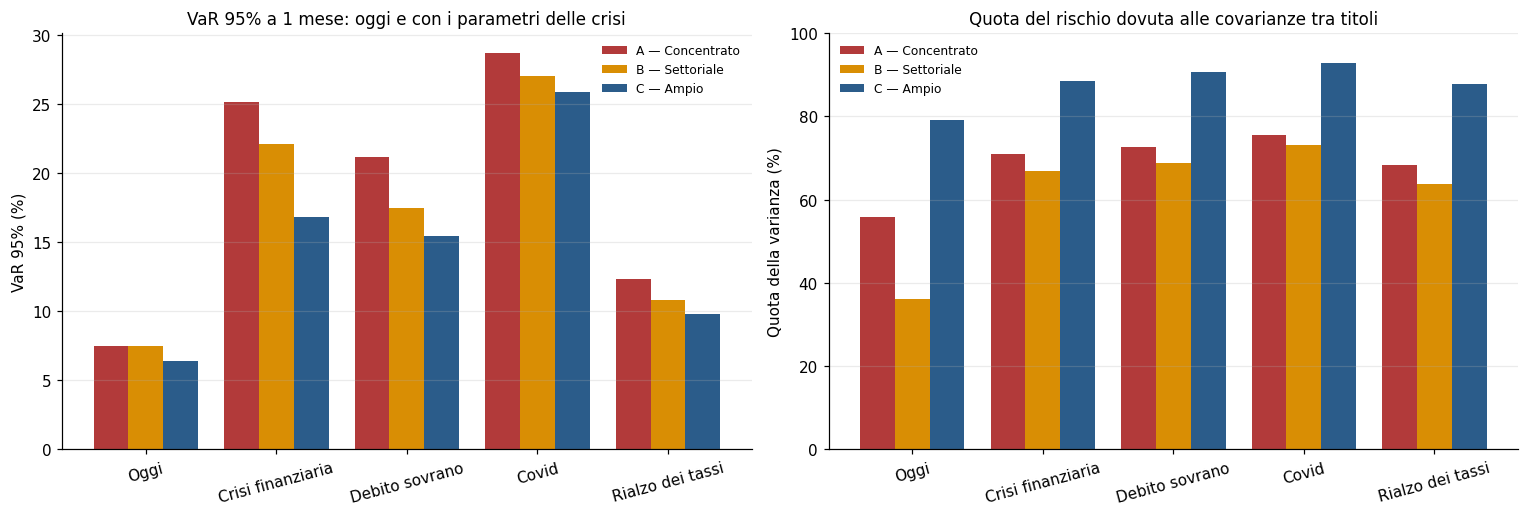

In [17]:
scenari_graf = ["Oggi"] + list(stress_p.index.get_level_values(0).unique())
nomi_p = list(PORTAFOGLI)
colori = ["#B23A3A", "#D98E04", "#2B5C8A"]
x = np.arange(len(scenari_graf))
larg = 0.8 / len(nomi_p)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for k, nome in enumerate(nomi_p):
    var_ = [confronto_p.loc[nome, "VaR 95%"]] + [stress_p.loc[(c, nome), "VaR 95%"] for c in scenari_graf[1:]]
    qc_ = [confronto_p.loc[nome, "Quota rischio da covarianze"]] + \
          [stress_p.loc[(c, nome), "Quota rischio da covarianze"] for c in scenari_graf[1:]]
    ax1.bar(x + (k - 1) * larg, np.array(var_) * 100, larg, color=colori[k], label=nome)
    ax2.bar(x + (k - 1) * larg, np.array(qc_) * 100, larg, color=colori[k], label=nome)
for ax, tit, yl in [(ax1, "VaR 95% a 1 mese: oggi e con i parametri delle crisi", "VaR 95% (%)"),
                    (ax2, "Quota del rischio dovuta alle covarianze tra titoli", "Quota della varianza (%)")]:
    ax.set_xticks(x, scenari_graf, rotation=15); ax.set_ylabel(yl); ax.set_title(tit, fontsize=11)
    ax.legend(frameon=False, fontsize=8); ax.grid(axis="x", visible=False)
ax2.set_ylim(0, 100)
plt.tight_layout(); plt.show()

### Come leggere i risultati

Per ciascuna ipotesi, il confronto da guardare:

- **H1 (oggi C < B < A).** Colonna *VaR 95%* della prima tabella. Confronta anche A con B: a parità di numero di titoli, quanto rischio elimina la sola diversificazione settoriale?
- **H2 (in crisi le differenze si riducono).** Nel grafico di sinistra: la distanza tra le barre è minore nelle crisi rispetto a oggi? La tabella *Verifica di H2* lo misura: se H2 è vera, il rapporto VaR(C)/VaR(A) in crisi è più vicino a 1 che oggi.
- **H3 (in C pesa di più la correlazione).** Nella tabella di stress, colonna *× solo correlazione*: è più alta per C che per A? E nel grafico di destra, la quota di rischio da covarianze di C è vicina al 100%?

Se le tre ipotesi sono confermate, la conclusione del progetto diventa: **la diversificazione riduce il rischio in tempi normali, ma il beneficio si restringe proprio nelle crisi; e più un portafoglio è diversificato, più il suo rischio dipende dalla correlazione, cioè da un fattore che la diversificazione stessa non può eliminare.**

**Limiti.** Pesi uguali per titolo: nel portafoglio C i settori non hanno lo stesso peso (finanza e utility contano 5 titoli ciascuno). La selezione di titoli quotati oggi e già presenti nel 2008 introduce una distorsione da sopravvivenza, che cresce con il numero di titoli.

## Step 7 — Backtesting: il modello funziona sui dati reali?

Fin qui abbiamo verificato che il codice calcola correttamente ciò che il modello prevede. Il backtesting risponde a una domanda diversa: **le previsioni del modello sono giuste?** Ogni giorno stimiamo il VaR usando *solo* i dati disponibili fino a quel momento, poi lo confrontiamo con la perdita effettivamente realizzata. Un'**eccezione** è un periodo in cui la perdita supera il VaR previsto.

Se il modello è corretto, le eccezioni devono essere:
1. **nel numero giusto**: circa il 5% dei periodi con un VaR al 95%, l'1% al 99%;
2. **indipendenti nel tempo**: sparse, non concentrate in grappoli durante le crisi.

**Test di Kupiec** (*proportion of failures*) — verifica la condizione 1. Con $x$ eccezioni su $T$ periodi e frequenza attesa $p = 1-\alpha$:

$$LR_{POF} = -2\ln\big[(1-p)^{T-x}p^{x}\big] + 2\ln\big[(1-\hat p)^{T-x}\hat p^{x}\big] \sim \chi^2(1), \qquad \hat p = x/T$$

**Test di Christoffersen** (*independence*) — verifica la condizione 2: la probabilità di un'eccezione oggi non deve dipendere dal fatto che ieri ci sia stata un'eccezione. Confronta $\pi_{01}$ (probabilità di eccezione dopo un giorno normale) con $\pi_{11}$ (probabilità di eccezione dopo un'eccezione): se $\pi_{11} \gg \pi_{01}$, le eccezioni arrivano a grappoli.

**Test congiunto** (*conditional coverage*): $LR_{CC} = LR_{POF} + LR_{IND} \sim \chi^2(2)$.

In tutti i test, un **p-value inferiore a 0,05** porta a rifiutare il modello.

**Scelte di impostazione.**
- **Nessuna informazione dal futuro.** Il VaR di ogni giorno usa solo i 2 anni precedenti. Il backtest inizia quindi 2 anni dopo l'inizio dei dati (2010): la crisi del 2008 serve solo da finestra di stima, mentre il 2011, il 2020 e il 2022 sono previsioni vere.
- **Giornaliero e mensile.** Il backtest principale è a 1 giorno (standard regolamentare, ~4.000 osservazioni, test potenti). Quello a 21 giorni usa **mesi non sovrapposti** (~200 osservazioni): finestre sovrapposte creerebbero grappoli di eccezioni artificiali e renderebbero i test non validi.
- **Formula chiusa al posto del Monte Carlo.** Rifare 10.000 simulazioni per ognuno dei ~4.000 giorni sarebbe lentissimo. Nello Step 4 abbiamo dimostrato che nel caso gaussiano i due metodi coincidono, quindi la scorciatoia è legittima. Inoltre, con pesi fissi, la varianza del portafoglio $w^\top\Sigma w$ coincide con la varianza della serie storica dei rendimenti di portafoglio $w^\top r_t$: basta una deviazione standard mobile.

**Due modelli a confronto.**
- **Gaussiano, finestra di 2 anni**: il modello usato finora, con la stessa volatilità per tutti i giorni della finestra.
- **EWMA (RiskMetrics, λ = 0,94)**: la varianza è una media che pesa di più i giorni recenti, $\sigma^2_t = \lambda\,\sigma^2_{t-1} + (1-\lambda)\,x^2_{t-1}$, quindi reagisce in pochi giorni a uno shock di volatilità. Serve da termine di paragone: se l'EWMA supera i test dove il modello a 2 anni fallisce, il problema è la volatilità costante; se falliscono entrambi, il problema è (anche) la normalità delle code.

In [18]:
from scipy.stats import chi2
from scipy.special import xlogy

FINESTRA = 252 * ANNI_DI_STIMA
LAMBDA_EWMA = 0.94

def test_kupiec(eccezioni, p):
    T, x = len(eccezioni), int(np.sum(eccezioni))
    p_hat = x / T
    lr = -2 * ((xlogy(T - x, 1 - p) + xlogy(x, p)) - (xlogy(T - x, 1 - p_hat) + xlogy(x, p_hat)))
    return lr, chi2.sf(lr, 1)

def test_christoffersen(eccezioni):
    e = np.asarray(eccezioni, dtype=int)
    ieri, oggi = e[:-1], e[1:]
    n00 = np.sum((ieri == 0) & (oggi == 0)); n01 = np.sum((ieri == 0) & (oggi == 1))
    n10 = np.sum((ieri == 1) & (oggi == 0)); n11 = np.sum((ieri == 1) & (oggi == 1))
    pi01 = n01 / (n00 + n01) if n00 + n01 > 0 else 0.0
    pi11 = n11 / (n10 + n11) if n10 + n11 > 0 else 0.0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_indip = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll_markov = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    lr = -2 * (ll_indip - ll_markov)
    return lr, chi2.sf(lr, 1), pi01, pi11

# Controllo dei test su casi noti: eccezioni indipendenti al 5% vs eccezioni a grappoli
_rng = np.random.default_rng(0)
_indip = _rng.random(4000) < 0.05
_grappoli = np.zeros(4000, dtype=bool); _grappoli[[*range(100, 120), *range(2000, 2040), *range(3500, 3540)]] = True
print("Controllo dei test (p-value):")
print(f"  eccezioni casuali al 5%      -> Kupiec {test_kupiec(_indip, .05)[1]:.2f}, "
      f"Christoffersen {test_christoffersen(_indip)[1]:.2f}  (attesi entrambi > 0,05)")
print(f"  100 eccezioni in 3 grappoli  -> Kupiec {test_kupiec(_grappoli, .05)[1]:.2f}, "
      f"Christoffersen {test_christoffersen(_grappoli)[1]:.4f}  (atteso: Christoffersen < 0,05)")

Controllo dei test (p-value):
  eccezioni casuali al 5%      -> Kupiec 0.39, Christoffersen 0.28  (attesi entrambi > 0,05)
  100 eccezioni in 3 grappoli  -> Kupiec 0.00, Christoffersen 0.0000  (atteso: Christoffersen < 0,05)


In [19]:
def previsioni(prezzi_p):
    # Rendimenti di portafoglio e VaR previsti, giorno per giorno, senza informazioni dal futuro.
    prezzi_p = prezzi_p.dropna()
    w = np.full(prezzi_p.shape[1], 1 / prezzi_p.shape[1])
    x = np.log(prezzi_p).diff().dropna() @ w              # rendimento log di portafoglio (lineare)
    R = prezzi_p.pct_change().dropna() @ w                # rendimento realizzato
    mu = 0.0 if MEDIA_ZERO else x.rolling(FINESTRA).mean().shift(1)
    sigma = {                                             # .shift(1): la previsione per il giorno t usa i dati fino a t-1
        "Gaussiano 2 anni": x.rolling(FINESTRA).std().shift(1),
        "EWMA": np.sqrt((x ** 2).ewm(alpha=1 - LAMBDA_EWMA, adjust=False).mean()).shift(1),
    }
    validi = sigma["Gaussiano 2 anni"].notna()           # stesso campione per entrambi i modelli
    if not np.isscalar(mu):
        mu = mu[validi]
    return prezzi_p, w, R[validi], {k: v[validi] for k, v in sigma.items()}, mu

def esito(p_pof, p_ind):
    if p_pof >= .05 and p_ind >= .05: return "Non rifiutato"
    if p_pof < .05 and p_ind < .05:  return "Rifiutato: frequenza e grappoli"
    return "Rifiutato: frequenza" if p_pof < .05 else "Rifiutato: grappoli"

def riga_test(eccezioni, alpha):
    lr_pof, p_pof = test_kupiec(eccezioni, 1 - alpha)
    lr_ind, p_ind, pi01, pi11 = test_christoffersen(eccezioni)
    return {"Osservazioni": len(eccezioni), "Eccezioni attese": len(eccezioni) * (1 - alpha),
            "Eccezioni osservate": int(np.sum(eccezioni)), "Frequenza": np.mean(eccezioni),
            "p Kupiec": p_pof, "p Christoffersen": p_ind, "p congiunto": chi2.sf(lr_pof + lr_ind, 2),
            "π01": pi01, "π11": pi11, "Esito": esito(p_pof, p_ind)}

PORTAFOGLI_BT = {"A — Concentrato": prezzi[TICKER], "C — Ampio": prezzi_u[PORTAFOGLI["C — Ampio"]]}
righe_bt, serie_bt = [], {}
for nome_p, prezzi_p in PORTAFOGLI_BT.items():
    prezzi_p, w, R, sigma, mu = previsioni(prezzi_p)
    date = prezzi_p.index
    for nome_m, sig in sigma.items():
        for a in LIVELLI:
            z = norm.ppf(1 - a)
            # --- giornaliero
            var_d = -(mu + z * sig)
            ecc = (R < -var_d).to_numpy()
            serie_bt[(nome_p, nome_m, a)] = pd.DataFrame({"R": R, "VaR": var_d, "eccezione": ecc})
            righe_bt.append({"Portafoglio": nome_p, "Modello": nome_m, "Orizzonte": "1 giorno",
                             "Livello": f"{a:.0%}", **riga_test(ecc, a)})
            # --- mensile, finestre non sovrapposte
            ecc_m = []
            i = date.get_loc(sig.index[0]) - 1              # origine: il giorno prima della prima previsione
            while i + ORIZZONTE < len(date):
                s_m = sig.loc[date[i + 1]]                  # stimata con i dati fino al giorno i
                m_m = mu if np.isscalar(mu) else mu.loc[date[i + 1]]
                var_m = -(ORIZZONTE * m_m + np.sqrt(ORIZZONTE) * z * s_m)
                realizzato = w @ (prezzi_p.iloc[i + ORIZZONTE].to_numpy() / prezzi_p.iloc[i].to_numpy() - 1)
                ecc_m.append(realizzato < -var_m)
                i += ORIZZONTE
            righe_bt.append({"Portafoglio": nome_p, "Modello": nome_m, "Orizzonte": "21 giorni",
                             "Livello": f"{a:.0%}", **riga_test(np.array(ecc_m), a)})

backtest_tab = pd.DataFrame(righe_bt).set_index(["Portafoglio", "Orizzonte", "Livello", "Modello"]).sort_index(
    level=[0, 1, 2], sort_remaining=False)
_ser = serie_bt[("A — Concentrato", "Gaussiano 2 anni", LIVELLI[0])]
print(f"Periodo di backtest (portafoglio A): {_ser.index[0].date()} – {_ser.index[-1].date()}")

def evidenzia(v):
    return "color: #B23A3A; font-weight: bold" if isinstance(v, float) and v < 0.05 else ""

display(backtest_tab.style
        .format({"Eccezioni attese": "{:.1f}", "Frequenza": "{:.2%}", "p Kupiec": "{:.3f}",
                 "p Christoffersen": "{:.3f}", "p congiunto": "{:.3f}", "π01": "{:.3f}", "π11": "{:.3f}"})
        .map(evidenzia, subset=["p Kupiec", "p Christoffersen", "p congiunto"]))

Periodo di backtest (portafoglio A): 2009-12-29 – 2026-11-06


### Dove cadono le eccezioni?

Il primo grafico mostra i rendimenti giornalieri del portafoglio A, il VaR al 99% previsto dai due modelli (con segno negativo, cioè come soglia di perdita) e le eccezioni del modello gaussiano. Il secondo applica il **semaforo di Basilea**: conta le eccezioni del VaR 99% a 1 giorno negli ultimi 250 giorni di borsa. Zona verde fino a 4 eccezioni (modello accettabile), gialla da 5 a 9, rossa da 10 in su (modello da rivedere).

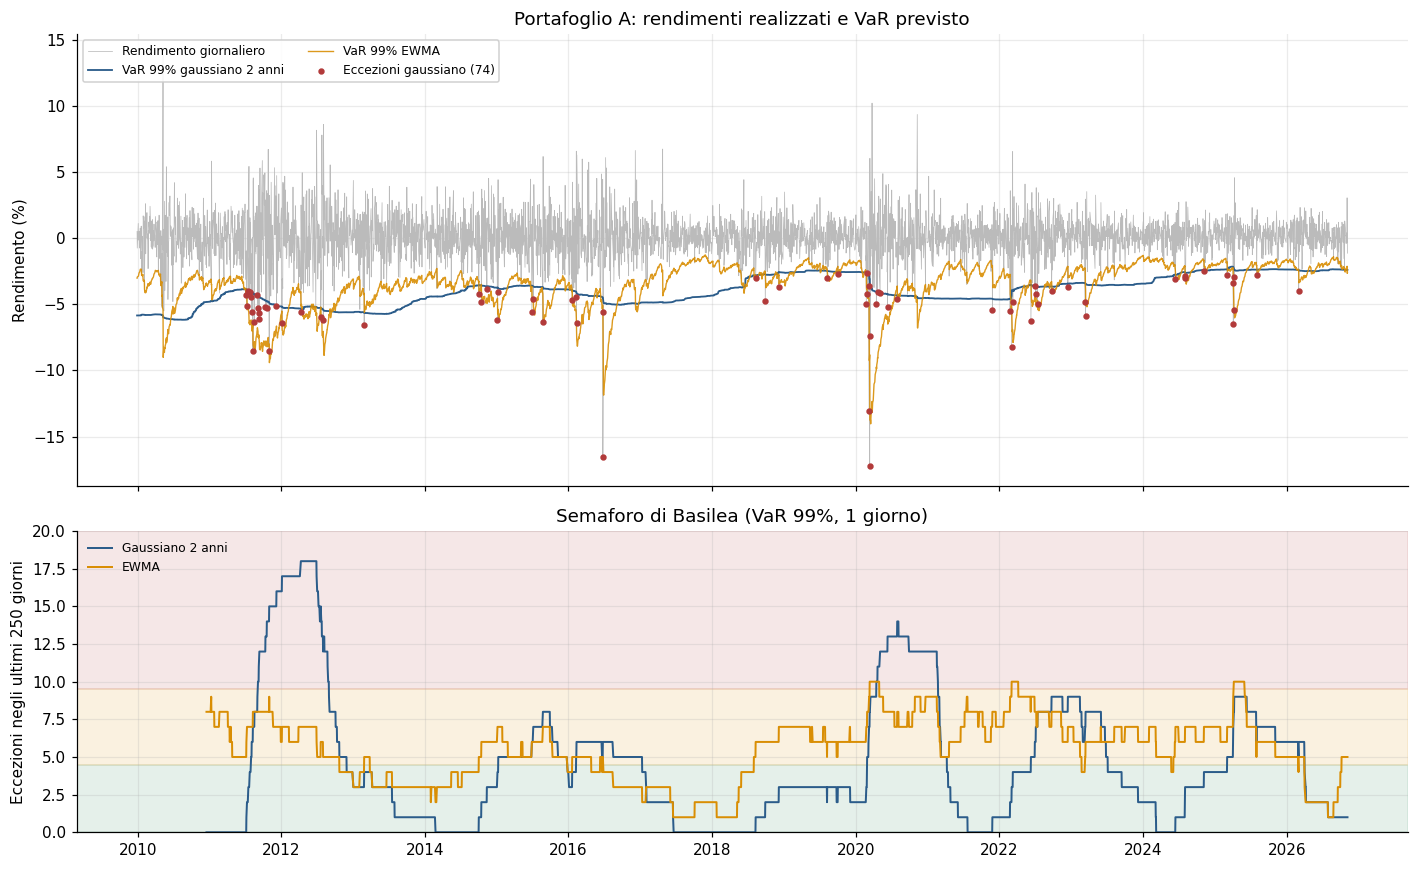

Quota del tempo in ciascuna zona del semaforo (portafoglio A):


,Verde (0-4),Gialla (5-9),Rossa (10+),Zona attuale
Gaussiano 2 anni,59%,29%,12%,verde
EWMA,30%,68%,2%,gialla



Eccezioni del VaR 99% a 1 giorno per anno (portafoglio A):


,Gaussiano 2 anni,EWMA,Giorni,Attese
Date,,,,
2009,0,0,2,0.0
2010,0,8,256,2.6
2011,16,7,256,2.6
2012,4,4,253,2.5
2013,1,3,252,2.5
2014,3,6,252,2.5
2015,5,5,255,2.6
2016,5,3,256,2.6
2017,0,2,254,2.5


In [20]:
liv = 0.99 if 0.99 in LIVELLI else max(LIVELLI)
gauss = serie_bt[("A — Concentrato", "Gaussiano 2 anni", liv)]
ewma = serie_bt[("A — Concentrato", "EWMA", liv)]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax1.plot(gauss.index, gauss["R"] * 100, color="#BBBBBB", lw=0.5, label="Rendimento giornaliero")
ax1.plot(gauss.index, -gauss["VaR"] * 100, color="#2B5C8A", lw=1.2, label=f"VaR {liv:.0%} gaussiano 2 anni")
ax1.plot(ewma.index, -ewma["VaR"] * 100, color="#D98E04", lw=0.9, alpha=0.9, label=f"VaR {liv:.0%} EWMA")
e = gauss[gauss["eccezione"]]
ax1.scatter(e.index, e["R"] * 100, color="#B23A3A", s=10, zorder=3, label=f"Eccezioni gaussiano ({len(e)})")
ax1.set_ylabel("Rendimento (%)"); ax1.set_title("Portafoglio A: rendimenti realizzati e VaR previsto")
ax1.legend(frameon=True, framealpha=0.9, fontsize=8, loc="upper left", ncol=2)

for nome_m, df, col in [("Gaussiano 2 anni", gauss, "#2B5C8A"), ("EWMA", ewma, "#D98E04")]:
    ax2.plot(df.index, df["eccezione"].rolling(250).sum(), color=col, lw=1.3, label=nome_m)
ymax = max(gauss["eccezione"].rolling(250).sum().max(), 12) + 2
ax2.axhspan(0, 4.5, color="#2E8B57", alpha=0.12); ax2.axhspan(4.5, 9.5, color="#D98E04", alpha=0.12)
ax2.axhspan(9.5, ymax, color="#B23A3A", alpha=0.12); ax2.set_ylim(0, ymax)
ax2.set_ylabel("Eccezioni negli ultimi 250 giorni"); ax2.set_title("Semaforo di Basilea (VaR 99%, 1 giorno)")
ax2.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

# Quota del tempo trascorsa in ciascuna zona e distribuzione delle eccezioni per anno
zone = {}
for nome_m, df in [("Gaussiano 2 anni", gauss), ("EWMA", ewma)]:
    conteggio = df["eccezione"].rolling(250).sum().dropna()
    zone[nome_m] = {"Verde (0-4)": (conteggio <= 4).mean(), "Gialla (5-9)": ((conteggio >= 5) & (conteggio <= 9)).mean(),
                    "Rossa (10+)": (conteggio >= 10).mean(), "Zona attuale": ("verde" if conteggio.iloc[-1] <= 4 else
                                                                             "gialla" if conteggio.iloc[-1] <= 9 else "rossa")}
print("Quota del tempo in ciascuna zona del semaforo (portafoglio A):")
display(pd.DataFrame(zone).T.style.format({"Verde (0-4)": "{:.0%}", "Gialla (5-9)": "{:.0%}", "Rossa (10+)": "{:.0%}"}))

per_anno = pd.DataFrame({nome_m: df["eccezione"].groupby(df.index.year).sum()
                         for nome_m, df in [("Gaussiano 2 anni", gauss), ("EWMA", ewma)]})
per_anno["Giorni"] = gauss["eccezione"].groupby(gauss.index.year).size()
per_anno["Attese"] = per_anno["Giorni"] * (1 - liv)
print(f"\nEccezioni del VaR {liv:.0%} a 1 giorno per anno (portafoglio A):")
display(per_anno.style.format({"Attese": "{:.1f}"}))

### Come leggere i risultati

**Tabella dei test.** I p-value in rosso indicano un rifiuto al 5%. Per ogni riga:
- *Kupiec* rifiuta se le eccezioni sono troppe (o troppo poche) rispetto alle attese;
- *Christoffersen* rifiuta se le eccezioni sono a grappoli: lo si vede anche dal confronto fra $\pi_{11}$ e $\pi_{01}$. Se dopo un'eccezione la probabilità di un'altra eccezione è molto più alta del normale, il modello non si accorge che il regime di volatilità è cambiato.

**Cosa ci si aspetta dalla teoria.**
- Il **modello gaussiano a 2 anni** dovrebbe essere rifiutato soprattutto dal test di Christoffersen: la finestra lunga reagisce lentamente, quindi nelle crisi il VaR resta troppo basso per settimane e le eccezioni si accumulano. Lo si vede nel grafico: i punti rossi si concentrano nel 2011, nel 2020 e nel 2022, e il semaforo entra in zona gialla o rossa proprio allora.
- Il **modello EWMA** dovrebbe ridurre i grappoli, perché alza il VaR pochi giorni dopo l'inizio di uno shock.
- Al **99%** entrambi i modelli potrebbero avere troppe eccezioni: la distribuzione normale sottostima le code reali. Questo è il problema che l'EWMA *non* risolve e che motiva l'estensione con la t di Student.

**Il backtest mensile** ha molte meno osservazioni (~200), quindi i test hanno poca potenza: un "non rifiutato" a 21 giorni è un'evidenza debole, mentre un rifiuto è un'evidenza forte.

**Il collegamento con gli Step 5 e 6.** Lo Step 5 ha mostrato che nelle crisi domina lo shock di volatilità; il backtest mostra se il modello riesce a *prevederlo in tempo*. Il confronto fra i portafogli A e C dice se un portafoglio diversificato è anche più facile da prevedere.

## Step 8 — Code spesse: il modello EWMA + t di Student

Il backtest dello Step 7 ha isolato due difetti del modello gaussiano: la **volatilità costante**, che produce eccezioni a grappoli e che l'EWMA corregge, e le **code troppo sottili** della distribuzione normale, che producono troppe eccezioni al 99% e che l'EWMA non corregge. Qui affrontiamo il secondo difetto.

**L'idea.** Dividiamo ogni rendimento di portafoglio per la volatilità EWMA prevista per quel giorno:

$$\varepsilon_t = \frac{x_t}{\sigma_t^{EWMA}}$$

Se l'EWMA cattura bene la dinamica della volatilità, i **residui standardizzati** $\varepsilon_t$ hanno volatilità circa costante: quello che resta è la *forma* della distribuzione. Se fossero normali, le perdite oltre 3 deviazioni standard sarebbero rarissime; se le code sono spesse, saranno molto più frequenti.

**La t di Student.** Modelliamo i residui con una t di Student, che ha un parametro in più rispetto alla normale: i **gradi di libertà** $\nu$. Più $\nu$ è basso, più le code sono spesse; per $\nu \to \infty$ la t diventa una normale. Per i rendimenti azionari giornalieri si trovano di solito valori fra 4 e 8.

Il VaR del modello EWMA + t diventa:

$$\text{VaR}_t = -\left(\mu + \sigma_t^{EWMA}\cdot s \cdot t_\nu^{-1}(1-\alpha)\right)$$

dove $s$ è il fattore di scala della t stimato sui residui.

**Nessuna informazione dal futuro.** $\nu$ e $s$ vengono ristimati ogni 21 giorni (massima verosimiglianza) usando **solo i residui precedenti** alla data di previsione.

**Orizzonte di 21 giorni.** La somma di 21 variabili t indipendenti **non** è una t: per il teorema del limite centrale, sommando molti giorni la distribuzione si avvicina alla normale. Il quantile mensile non si ottiene quindi scalando per $\sqrt{21}$ il quantile giornaliero, ma simulando la somma di 21 estrazioni t.

In [21]:
from scipy.stats import t as student_t, kurtosis

AGGIORNA_OGNI = 21     # giorni fra una stima di nu e la successiva
BURN_IN = 50           # primi residui scartati: l'EWMA ha bisogno di qualche giorno per stabilizzarsi
MIN_RESIDUI = 250      # residui minimi per stimare nu

def stima_t(eps):
    # Gradi di libertà e scala di una t di Student centrata in zero (massima verosimiglianza).
    nu, _, scala = student_t.fit(eps, floc=0)
    return float(np.clip(nu, 2.1, 200)), float(scala)

_cache_somma = {}
def quantili_somma_t(nu, n_giorni=ORIZZONTE, sims=50_000):
    # Quantili al 5% e all'1% della somma di n_giorni variabili t(nu) indipendenti (scala 1), per simulazione.
    chiave = round(nu * 4) / 4                       # arrotonda nu a 0,25 per riusare le simulazioni
    if chiave not in _cache_somma:
        somma = student_t.rvs(chiave, size=(sims, n_giorni), random_state=np.random.default_rng(SEED)).sum(1)
        _cache_somma[chiave] = {a: np.quantile(somma, 1 - a) for a in LIVELLI}
    return _cache_somma[chiave]

def modello_ewma_t(prezzi_p):
    prezzi_p = prezzi_p.dropna()
    w = np.full(prezzi_p.shape[1], 1 / prezzi_p.shape[1])
    x = np.log(prezzi_p).diff().dropna() @ w
    R = prezzi_p.pct_change().dropna() @ w
    sig = np.sqrt((x ** 2).ewm(alpha=1 - LAMBDA_EWMA, adjust=False).mean()).shift(1)
    eps = (x / sig).dropna().iloc[BURN_IN:]                      # residui standardizzati
    validi = x.rolling(FINESTRA).std().shift(1).notna()        # stesso campione dello Step 7
    date_bt = x.index[validi]
    stime = {}
    for d in date_bt[::AGGIORNA_OGNI]:
        passati = eps[eps.index < d].to_numpy()                 # solo residui già osservati
        if len(passati) >= MIN_RESIDUI:
            stime[d] = stima_t(passati)
    par = pd.DataFrame(stime, index=["nu", "scala"]).T.reindex(date_bt).ffill().bfill()
    mu = 0.0 if MEDIA_ZERO else x.rolling(FINESTRA).mean().shift(1)[validi]
    return prezzi_p, w, R[validi], sig[validi], par, mu, eps

nomi_modelli = {"Gaussiano 2 anni": "Gaussiano 2 anni", "EWMA": "EWMA normale"}
righe_t, info_t = [], {}
for nome_p, prezzi_p in PORTAFOGLI_BT.items():
    prezzi_p, w, R, sig, par, mu, eps = modello_ewma_t(prezzi_p)
    info_t[nome_p] = (par, eps)
    date = prezzi_p.index
    for a in LIVELLI:
        # --- giornaliero
        var_d = -(mu + sig * par["scala"] * student_t.ppf(1 - a, par["nu"]))
        ecc = (R < -var_d).to_numpy()
        serie_bt[(nome_p, "EWMA + t", a)] = pd.DataFrame({"R": R, "VaR": var_d, "eccezione": ecc})
        righe_t.append({"Portafoglio": nome_p, "Modello": "EWMA + t", "Orizzonte": "1 giorno",
                        "Livello": f"{a:.0%}", **riga_test(ecc, a)})
        # --- mensile, finestre non sovrapposte
        ecc_m = []
        i = date.get_loc(sig.index[0]) - 1
        while i + ORIZZONTE < len(date):
            d = date[i + 1]
            q = quantili_somma_t(par.loc[d, "nu"])[a]
            m_m = mu if np.isscalar(mu) else mu.loc[d]
            var_m = -(ORIZZONTE * m_m + sig.loc[d] * par.loc[d, "scala"] * q)
            realizzato = w @ (prezzi_p.iloc[i + ORIZZONTE].to_numpy() / prezzi_p.iloc[i].to_numpy() - 1)
            ecc_m.append(realizzato < -var_m)
            i += ORIZZONTE
        righe_t.append({"Portafoglio": nome_p, "Modello": "EWMA + t", "Orizzonte": "21 giorni",
                        "Livello": f"{a:.0%}", **riga_test(np.array(ecc_m), a)})

par_A, eps_A = info_t["A — Concentrato"]
print(f"Gradi di libertà stimati (portafoglio A): da {par_A['nu'].min():.1f} a {par_A['nu'].max():.1f}, "
      f"ultimo valore {par_A['nu'].iloc[-1]:.1f}")
print(f"Curtosi in eccesso dei residui standardizzati (normale = 0): {kurtosis(eps_A):.2f}")

Gradi di libertà stimati (portafoglio A): da 5.7 a 10.3, ultimo valore 5.9
Curtosi in eccesso dei residui standardizzati (normale = 0): 2.89


### Le code dei residui: normale o t?

Il grafico confronta la distribuzione dei residui standardizzati del portafoglio A con la normale e con la t stimata. L'asse verticale è **logaritmico**: serve a rendere visibili le code, che su una scala normale sarebbero schiacciate sullo zero. Nelle code la normale scende molto più rapidamente dei dati; la t dovrebbe seguirli.

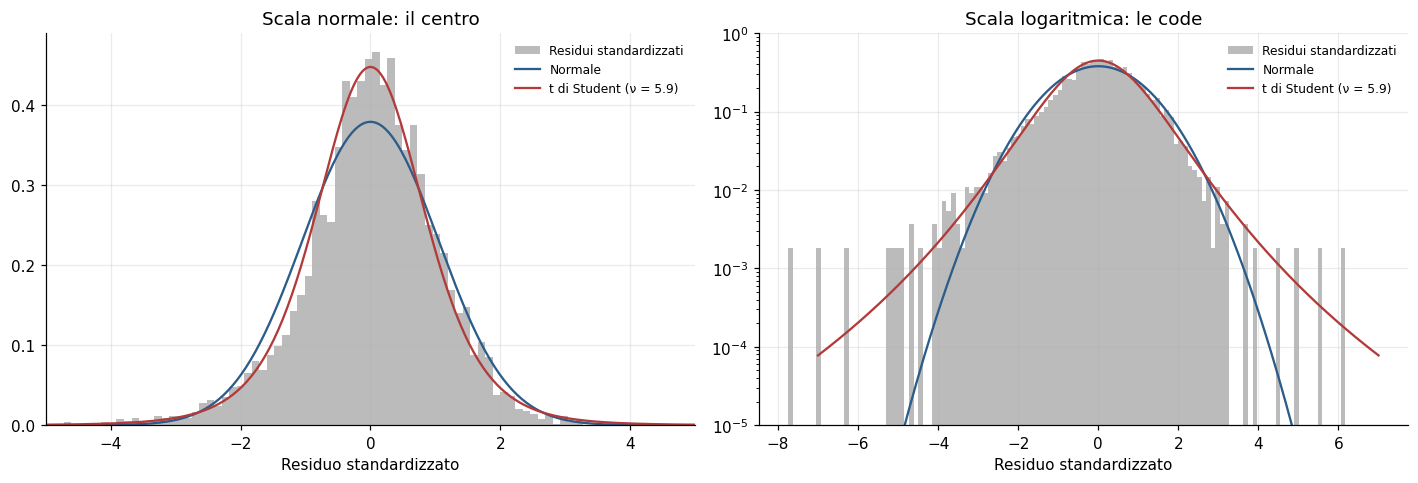

Frequenza di residui oltre k deviazioni standard (portafoglio A):
  oltre 3: osservata 1.034%  |  normale 0.2700%  |  rapporto ×4
  oltre 4: osservata 0.296%  |  normale 0.0063%  |  rapporto ×47
  oltre 5: osservata 0.127%  |  normale 0.0001%  |  rapporto ×2,209


In [22]:
nu_fin, scala_fin = stima_t(eps_A.to_numpy())
griglia_x = np.linspace(-7, 7, 400)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, log in [(ax1, False), (ax2, True)]:
    ax.hist(eps_A, bins=120, density=True, color="#BBBBBB", label="Residui standardizzati")
    ax.plot(griglia_x, norm.pdf(griglia_x, 0, eps_A.std()), color="#2B5C8A", lw=1.5, label="Normale")
    ax.plot(griglia_x, student_t.pdf(griglia_x, nu_fin, 0, scala_fin), color="#B23A3A", lw=1.5,
            label=f"t di Student (ν = {nu_fin:.1f})")
    ax.set_xlabel("Residuo standardizzato")
    if log:
        ax.set_yscale("log"); ax.set_ylim(1e-5, 1); ax.set_title("Scala logaritmica: le code")
    else:
        ax.set_xlim(-5, 5); ax.set_title("Scala normale: il centro")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

oltre = {k: (np.abs(eps_A / eps_A.std()) > k).mean() for k in [3, 4, 5]}
print("Frequenza di residui oltre k deviazioni standard (portafoglio A):")
for k, f in oltre.items():
    print(f"  oltre {k}: osservata {f:.3%}  |  normale {2 * norm.sf(k):.4%}  |  rapporto ×{f / (2 * norm.sf(k)):,.0f}")

### Backtest: i tre modelli a confronto

La tabella riunisce i risultati dello Step 7 e quelli del nuovo modello. La domanda è se l'EWMA + t risolva **entrambi** i difetti: il numero di eccezioni (Kupiec) e i grappoli (Christoffersen).

In [23]:
righe_tutte = [{**r, "Modello": nomi_modelli[r["Modello"]]} for r in righe_bt] + righe_t
ordine_modelli = {"Gaussiano 2 anni": 0, "EWMA normale": 1, "EWMA + t": 2}
backtest_finale = (pd.DataFrame(righe_tutte)
                   .assign(_o=lambda d: d["Modello"].map(ordine_modelli))
                   .sort_values(["Portafoglio", "Orizzonte", "Livello", "_o"]).drop(columns="_o")
                   .set_index(["Portafoglio", "Orizzonte", "Livello", "Modello"]))
display(backtest_finale.style
        .format({"Eccezioni attese": "{:.1f}", "Frequenza": "{:.2%}", "p Kupiec": "{:.3f}",
                 "p Christoffersen": "{:.3f}", "p congiunto": "{:.3f}", "π01": "{:.3f}", "π11": "{:.3f}"})
        .map(evidenzia, subset=["p Kupiec", "p Christoffersen", "p congiunto"]))

# Sintesi: quanti test (su 8 combinazioni portafoglio x orizzonte x livello) ogni modello supera
_bf = backtest_finale.reset_index()
sintesi = pd.DataFrame({m: {"Combinazioni": len(d), "Kupiec superato": int((d["p Kupiec"] >= .05).sum()),
                            "Christoffersen superato": int((d["p Christoffersen"] >= .05).sum()),
                            "Entrambi superati": int(((d["p Kupiec"] >= .05) & (d["p Christoffersen"] >= .05)).sum())}
                        for m in ordine_modelli for d in [_bf[_bf["Modello"] == m]]}).T
print("\nSINTESI: numero di combinazioni (portafoglio × orizzonte × livello) in cui il modello supera i test")
display(sintesi)


SINTESI: numero di combinazioni (portafoglio × orizzonte × livello) in cui il modello supera i test


,Combinazioni,Kupiec superato,Christoffersen superato,Entrambi superati
Gaussiano 2 anni,8,5,4,4
EWMA normale,8,3,6,3
EWMA + t,8,6,6,4


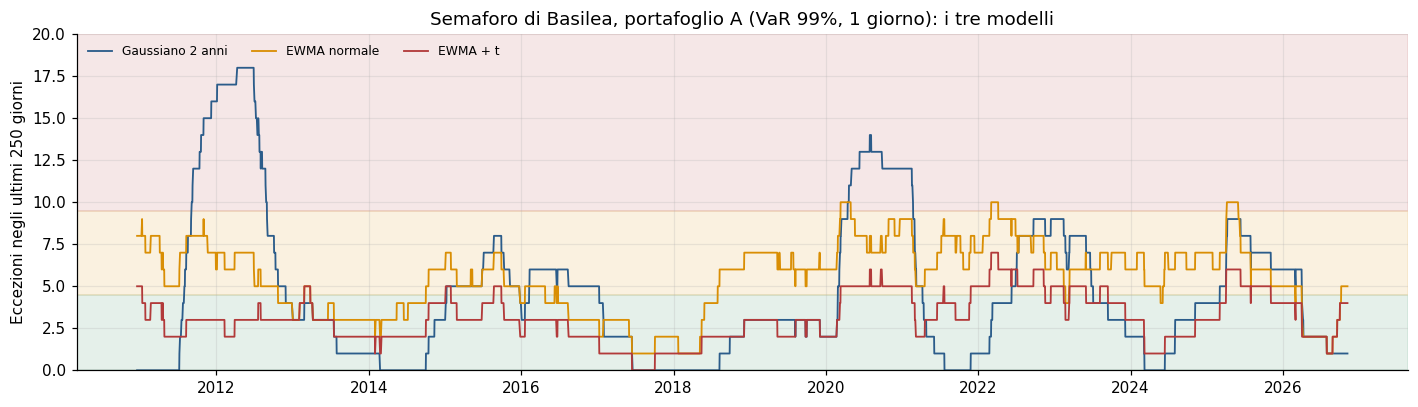

Quota del tempo in ciascuna zona del semaforo (portafoglio A):


,Verde (0-4),Gialla (5-9),Rossa (10+)
Gaussiano 2 anni,59%,29%,12%
EWMA normale,30%,68%,2%
EWMA + t,79%,21%,0%



Eccezioni del VaR 99% a 1 giorno per anno (portafoglio A):


,Gaussiano 2 anni,EWMA normale,EWMA + t,Attese
Date,,,,
2009,0,0,0,0.0
2010,0,8,5,2.6
2011,16,7,3,2.6
2012,4,4,3,2.5
2013,1,3,2,2.5
2014,3,6,4,2.5
2015,5,5,3,2.6
2016,5,3,2,2.6
2017,0,2,1,2.5


In [24]:
liv = 0.99 if 0.99 in LIVELLI else max(LIVELLI)
modelli_graf = [("Gaussiano 2 anni", "Gaussiano 2 anni", "#2B5C8A"), ("EWMA", "EWMA normale", "#D98E04"),
                ("EWMA + t", "EWMA + t", "#B23A3A")]

fig, ax = plt.subplots(figsize=(13, 3.8))
ymax = 12
for chiave, etichetta, col in modelli_graf:
    conteggio = serie_bt[("A — Concentrato", chiave, liv)]["eccezione"].rolling(250).sum()
    ax.plot(conteggio.index, conteggio, color=col, lw=1.2, label=etichetta)
    ymax = max(ymax, conteggio.max() + 2)
ax.axhspan(0, 4.5, color="#2E8B57", alpha=0.12); ax.axhspan(4.5, 9.5, color="#D98E04", alpha=0.12)
ax.axhspan(9.5, ymax, color="#B23A3A", alpha=0.12); ax.set_ylim(0, ymax)
ax.set_ylabel("Eccezioni negli ultimi 250 giorni")
ax.set_title(f"Semaforo di Basilea, portafoglio A (VaR {liv:.0%}, 1 giorno): i tre modelli")
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

zone_fin, anni_fin = {}, {}
for chiave, etichetta, _ in modelli_graf:
    df = serie_bt[("A — Concentrato", chiave, liv)]
    c = df["eccezione"].rolling(250).sum().dropna()
    zone_fin[etichetta] = {"Verde (0-4)": (c <= 4).mean(), "Gialla (5-9)": ((c >= 5) & (c <= 9)).mean(),
                           "Rossa (10+)": (c >= 10).mean()}
    anni_fin[etichetta] = df["eccezione"].groupby(df.index.year).sum()
print("Quota del tempo in ciascuna zona del semaforo (portafoglio A):")
display(pd.DataFrame(zone_fin).T.style.format("{:.0%}"))
anni_fin = pd.DataFrame(anni_fin)
anni_fin["Attese"] = df["eccezione"].groupby(df.index.year).size() * (1 - liv)
print(f"\nEccezioni del VaR {liv:.0%} a 1 giorno per anno (portafoglio A):")
display(anni_fin.style.format({"Attese": "{:.1f}"}))

### VaR ed ES con la t multivariata (Monte Carlo)

Infine ricalcoliamo VaR ed ES del portafoglio come nello Step 4, sostituendo la normale multivariata con una **t multivariata** con la stessa matrice di covarianza. Così l'unica differenza fra i due modelli è la forma delle code.

**Come si simula.** Si genera il vettore normale correlato $Lz$ come prima, poi lo si divide per $\sqrt{W/\nu}$, dove $W$ è una chi-quadro con $\nu$ gradi di libertà **comune a tutti i titoli**:

$$X = \sqrt{\tfrac{\nu-2}{\nu}}\;\frac{L z}{\sqrt{W/\nu}}$$

Il fattore $\sqrt{(\nu-2)/\nu}$ riporta la varianza a quella della normale. Poiché $W$ è comune, nei giorni in cui $W$ è piccolo **tutti i titoli** subiscono insieme uno shock ampio: è la **dipendenza nelle code**, che la normale multivariata non ha. Un portafoglio di titoli con distribuzione t multivariata ha a sua volta una distribuzione t con gli stessi $\nu$: per questo usiamo il $\nu$ stimato sul portafoglio.

Confrontiamo i due modelli a **1 giorno** e a **21 giorni**, per vedere quanto l'aggregazione temporale attenui le code.

In [25]:
N_SIM_T = 100_000      # più scenari che nello Step 4: le code al 99% richiedono più precisione

def simula_percorsi(cov, nu, giorni, n, seed):
    # Rendimenti log cumulati: normale e t multivariata con la stessa covarianza e gli stessi z.
    rng = np.random.default_rng(seed)
    L = np.linalg.cholesky(cov)
    normale = np.zeros((n, cov.shape[0])); t_mv = np.zeros_like(normale)
    for _ in range(giorni):                                        # un giorno alla volta: meno memoria
        z = rng.standard_normal((n, cov.shape[0])) @ L.T
        W = rng.chisquare(nu, size=(n, 1))
        normale += z
        t_mv += np.sqrt((nu - 2) / nu) * z / np.sqrt(W / nu)
    return giorni * mu_sim + normale, giorni * mu_sim + t_mv

# Controllo: la t multivariata deve avere la stessa varianza della normale
_n, _t = simula_percorsi(cov_g, nu_fin, 1, 200_000, 99)
print(f"ν usato: {nu_fin:.1f}  |  controllo: varianza t / varianza normale del portafoglio = "
      f"{(_t @ PESI).var() / (_n @ PESI).var():.3f} (atteso ≈ 1)")

righe_mc = []
for giorni in [1, ORIZZONTE]:
    sc_n, sc_t = simula_percorsi(cov_g, nu_fin, giorni, N_SIM_T, SEED)
    rp_n, rp_t = rendimento_portafoglio(sc_n, PESI), rendimento_portafoglio(sc_t, PESI)
    for a in LIVELLI:
        vn, en = var_es(rp_n, a); vt, et = var_es(rp_t, a)
        righe_mc.append({"Orizzonte": f"{giorni} giorn{'o' if giorni == 1 else 'i'}", "Livello": f"{a:.0%}",
                         "VaR normale": vn, "VaR t": vt, "VaR t / normale": vt / vn,
                         "ES normale": en, "ES t": et, "ES t / normale": et / en})
mc_t = pd.DataFrame(righe_mc).set_index(["Orizzonte", "Livello"])
display(mc_t.style.format({c: "{:.2%}" for c in mc_t.columns if "/" not in c} |
                          {c: "×{:.2f}" for c in mc_t.columns if "/" in c}))

ν usato: 5.9  |  controllo: varianza t / varianza normale del portafoglio = 1.005 (atteso ≈ 1)


### Come leggere i risultati

**1. Le code dei residui.** Se la curtosi in eccesso è nettamente positiva e i residui oltre 4–5 deviazioni standard sono decine o centinaia di volte più frequenti di quanto preveda la normale, le code spesse sono confermate. Un $\nu$ stimato fra 4 e 8 è tipico dei mercati azionari.

**2. Il backtest.** La tabella di sintesi dice quanti test supera ciascun modello. Se il ragionamento degli Step 7–8 è corretto:
- il *gaussiano a 2 anni* fallisce soprattutto per i grappoli;
- l'*EWMA normale* risolve i grappoli ma ha troppe eccezioni al 99%;
- l'*EWMA + t* dovrebbe risolvere entrambi i problemi, almeno al 99% a un giorno, cioè proprio dove la normale falliva di più.

Anche il semaforo di Basilea dovrebbe mostrare l'EWMA + t più spesso in zona verde.

**3. Il Monte Carlo con la t.** A parità di varianza, la t sposta probabilità verso il centro *e* verso le code estreme. Di conseguenza:
- al **95%** il VaR t può essere simile o persino *inferiore* a quello normale, perché il 95% non è ancora "coda estrema";
- al **99%**, e ancor più per l'**ES**, la t dà perdite più alte: l'ES è la misura più sensibile alle code, ed è uno dei motivi per cui la regolamentazione è passata dal VaR all'ES;
- a **21 giorni** le differenze si riducono, perché la somma di molti giorni indipendenti si avvicina alla normale. Questo spiega anche perché, nello Step 7, il backtest mensile del modello gaussiano veniva rifiutato poco.

**Un limite importante.** La t multivariata del Monte Carlo usa una covarianza costante: le code spesse "di breve periodo" si attenuano col tempo. Nella realtà le code mensili restano spesse anche perché la volatilità cambia (gli shock si accumulano nelle crisi), ed è l'EWMA a catturare questo effetto. Il modello più completo è la loro combinazione dinamica, che è proprio quella sottoposta a backtest qui sopra.

## Step 9 — Scala, spessore e asimmetria delle code: da dove viene il miglioramento?

Lo Step 8 ha mostrato che il modello EWMA + t riduce molto gli errori del VaR. Ma il passaggio dall'EWMA normale all'EWMA + t cambia **due cose insieme**:
1. la **scala** dei residui: la t viene stimata con un proprio fattore di scala, quindi ricalibra anche la varianza;
2. la **forma** della distribuzione: code più spesse.

E restano due difetti: al 99% le eccezioni sono ancora troppe, e la coda sinistra dei residui sembra più spessa della destra (**asimmetria**), mentre la t è simmetrica.

Per separare gli effetti aggiungiamo due modelli, entrambi con la stessa volatilità EWMA e lo stesso calendario di stima (ogni 21 giorni, solo dati passati):

| Modello | Distribuzione dei residui | Cosa isola |
|---|---|---|
| **EWMA normale ricalibrato** | normale, con la deviazione standard *effettiva* dei residui passati | l'effetto della sola **scala** |
| **EWMA + t** (Step 8) | t di Student simmetrica | + l'effetto dello **spessore** delle code |
| **Filtered Historical Simulation (FHS)** | distribuzione **empirica** dei residui passati, nessuna ipotesi sulla forma | + l'effetto dell'**asimmetria** |

Nella FHS il VaR è il quantile empirico dei residui passati moltiplicato per la volatilità EWMA di oggi:

$$\text{VaR}_t = -\left(\mu + \sigma^{EWMA}_t \cdot \hat q_{1-\alpha}(\varepsilon_{s<t})\right)$$

Per l'orizzonte di 21 giorni, la somma dei residui si ottiene ricampionando 21 residui passati (bootstrap).

Il percorso **EWMA normale → ricalibrato → t → FHS** scompone così il miglioramento in tre contributi: scala, spessore, asimmetria.

In [26]:
from scipy.stats import skew

def basi_residui(prezzi_p):
    prezzi_p = prezzi_p.dropna()
    w = np.full(prezzi_p.shape[1], 1 / prezzi_p.shape[1])
    x = np.log(prezzi_p).diff().dropna() @ w
    R = prezzi_p.pct_change().dropna() @ w
    sig = np.sqrt((x ** 2).ewm(alpha=1 - LAMBDA_EWMA, adjust=False).mean()).shift(1)
    eps = (x / sig).dropna().iloc[BURN_IN:]
    validi = x.rolling(FINESTRA).std().shift(1).notna()
    mu = 0.0 if MEDIA_ZERO else x.rolling(FINESTRA).mean().shift(1)[validi]
    return prezzi_p, w, R[validi], sig[validi], eps, mu

# --- Diagnosi dell'asimmetria (portafoglio A, tutto il campione: è una descrizione, non una previsione)
_, _, _, _, eps_diag, _ = basi_residui(PORTAFOGLI_BT["A — Concentrato"])
e_std = (eps_diag / eps_diag.std()).to_numpy()
nu_d, sc_d = stima_t(eps_diag.to_numpy())
print(f"Asimmetria (skewness) dei residui standardizzati: {skew(e_std):.2f}   (simmetria = 0; negativa = coda sinistra più lunga)")
righe_asim = []
for k in [2, 3, 4]:
    soglia = k * eps_diag.std()
    atteso_t = student_t.sf(soglia, nu_d, 0, sc_d) * len(eps_diag)       # per lato: la t è simmetrica
    righe_asim.append({"Soglia": f"oltre {k} dev. std.", "Coda sinistra (perdite)": int((eps_diag < -soglia).sum()),
                       "Coda destra (guadagni)": int((eps_diag > soglia).sum()), "Attesi con la t, per lato": atteso_t})
display(pd.DataFrame(righe_asim).set_index("Soglia").style.format({"Attesi con la t, per lato": "{:.1f}"}))

Asimmetria (skewness) dei residui standardizzati: -0.50   (simmetria = 0; negativa = coda sinistra più lunga)


,Coda sinistra (perdite),Coda destra (guadagni),"Attesi con la t, per lato"
Soglia,,,
oltre 2 dev. std.,145,81,117.7
oltre 3 dev. std.,38,11,24.9
oltre 4 dev. std.,10,4,6.6


In [27]:
SIM_FHS = 20_000       # ricampionamenti per il quantile mensile della FHS

righe_9 = []
for nome_p, prezzi_p in PORTAFOGLI_BT.items():
    prezzi_p, w, R, sig, eps, mu = basi_residui(prezzi_p)
    date_bt = sig.index
    date = prezzi_p.index
    # stime periodiche, solo con i residui precedenti alla data
    stime = {}
    for d in date_bt[::AGGIORNA_OGNI]:
        passati = eps[eps.index < d].to_numpy()
        if len(passati) >= MIN_RESIDUI:
            stime[d] = {"dev_std": passati.std(ddof=1), **{f"q{a}": np.quantile(passati, 1 - a) for a in LIVELLI}}
    st = pd.DataFrame(stime).T.reindex(date_bt).ffill().bfill()
    rng_fhs = np.random.default_rng(SEED)

    for a in LIVELLI:
        z = norm.ppf(1 - a)
        var_ric = -(mu + sig * st["dev_std"] * z)
        var_fhs = -(mu + sig * st[f"q{a}"])
        for nome_m, var_d in [("EWMA normale ricalibrato", var_ric), ("FHS", var_fhs)]:
            ecc = (R < -var_d).to_numpy()
            serie_bt[(nome_p, nome_m, a)] = pd.DataFrame({"R": R, "VaR": var_d, "eccezione": ecc})
            righe_9.append({"Portafoglio": nome_p, "Modello": nome_m, "Orizzonte": "1 giorno",
                            "Livello": f"{a:.0%}", **riga_test(ecc, a)})
        # --- mensile, finestre non sovrapposte
        ecc_ric, ecc_fhs = [], []
        i = date.get_loc(date_bt[0]) - 1
        while i + ORIZZONTE < len(date):
            d = date[i + 1]
            m_m = mu if np.isscalar(mu) else mu.loc[d]
            realizzato = w @ (prezzi_p.iloc[i + ORIZZONTE].to_numpy() / prezzi_p.iloc[i].to_numpy() - 1)
            var_r = -(ORIZZONTE * m_m + np.sqrt(ORIZZONTE) * sig.loc[d] * st.loc[d, "dev_std"] * z)
            passati = eps[eps.index < d].to_numpy()
            somme = rng_fhs.choice(passati, size=(SIM_FHS, ORIZZONTE), replace=True).sum(1)
            var_f = -(ORIZZONTE * m_m + sig.loc[d] * np.quantile(somme, 1 - a))
            ecc_ric.append(realizzato < -var_r); ecc_fhs.append(realizzato < -var_f)
            i += ORIZZONTE
        for nome_m, e_m in [("EWMA normale ricalibrato", ecc_ric), ("FHS", ecc_fhs)]:
            righe_9.append({"Portafoglio": nome_p, "Modello": nome_m, "Orizzonte": "21 giorni",
                            "Livello": f"{a:.0%}", **riga_test(np.array(e_m), a)})

ordine_9 = {"Gaussiano 2 anni": 0, "EWMA normale": 1, "EWMA normale ricalibrato": 2, "EWMA + t": 3, "FHS": 4}
backtest_9 = (pd.concat([backtest_finale.reset_index(), pd.DataFrame(righe_9)])
              .assign(_o=lambda d: d["Modello"].map(ordine_9))
              .sort_values(["Portafoglio", "Orizzonte", "Livello", "_o"]).drop(columns="_o")
              .set_index(["Portafoglio", "Orizzonte", "Livello", "Modello"]))
display(backtest_9.style
        .format({"Eccezioni attese": "{:.1f}", "Frequenza": "{:.2%}", "p Kupiec": "{:.3f}",
                 "p Christoffersen": "{:.3f}", "p congiunto": "{:.3f}", "π01": "{:.3f}", "π11": "{:.3f}"})
        .map(evidenzia, subset=["p Kupiec", "p Christoffersen", "p congiunto"]))

### Scomposizione del miglioramento

La tabella seguente legge il backtest a **1 giorno** (il più informativo, con ~4.300 osservazioni) come una scala di modelli. Per ciascun modello riporta l'**eccesso di eccezioni** rispetto alle attese: 0% è il valore ideale, un valore positivo indica un VaR troppo basso, uno negativo un VaR troppo prudente.

Le differenze fra righe consecutive misurano i singoli contributi:
- *EWMA normale → ricalibrato*: effetto della **scala**;
- *ricalibrato → EWMA + t*: effetto dello **spessore** delle code;
- *EWMA + t → FHS*: effetto dell'**asimmetria** (e di ogni altra differenza fra la t e la distribuzione reale).

In [28]:
_b = backtest_9.reset_index()
_g = _b[_b["Orizzonte"] == "1 giorno"]
scala_modelli = (_g.assign(Eccesso=lambda d: d["Eccezioni osservate"] / d["Eccezioni attese"] - 1)
                 .pivot_table(index="Modello", columns=["Portafoglio", "Livello"], values="Eccesso")
                 .loc[list(ordine_9)])
print("Eccesso di eccezioni rispetto alle attese, VaR a 1 giorno (0% = perfetto)")
display(scala_modelli.style.format("{:+.0%}").background_gradient(cmap="RdYlGn_r", vmin=-0.6, vmax=0.6, axis=None))

sintesi_9 = pd.DataFrame({m: {
    "Superati (1 giorno, su 4)": int(((d["Orizzonte"] == "1 giorno") & (d["p Kupiec"] >= .05) & (d["p Christoffersen"] >= .05)).sum()),
    "Superati (21 giorni, su 4)": int(((d["Orizzonte"] == "21 giorni") & (d["p Kupiec"] >= .05) & (d["p Christoffersen"] >= .05)).sum()),
    "Kupiec superato (su 8)": int((d["p Kupiec"] >= .05).sum()),
    "Christoffersen superato (su 8)": int((d["p Christoffersen"] >= .05).sum())}
    for m in ordine_9 for d in [_b[_b["Modello"] == m]]}).T
print("\nSINTESI: combinazioni in cui il modello supera entrambi i test (Kupiec e Christoffersen)")
display(sintesi_9)

Eccesso di eccezioni rispetto alle attese, VaR a 1 giorno (0% = perfetto)



SINTESI: combinazioni in cui il modello supera entrambi i test (Kupiec e Christoffersen)


,"Superati (1 giorno, su 4)","Superati (21 giorni, su 4)",Kupiec superato (su 8),Christoffersen superato (su 8)
Gaussiano 2 anni,0,4,5,4
EWMA normale,0,3,3,6
EWMA normale ricalibrato,0,4,6,6
EWMA + t,0,4,6,6
FHS,2,4,7,6


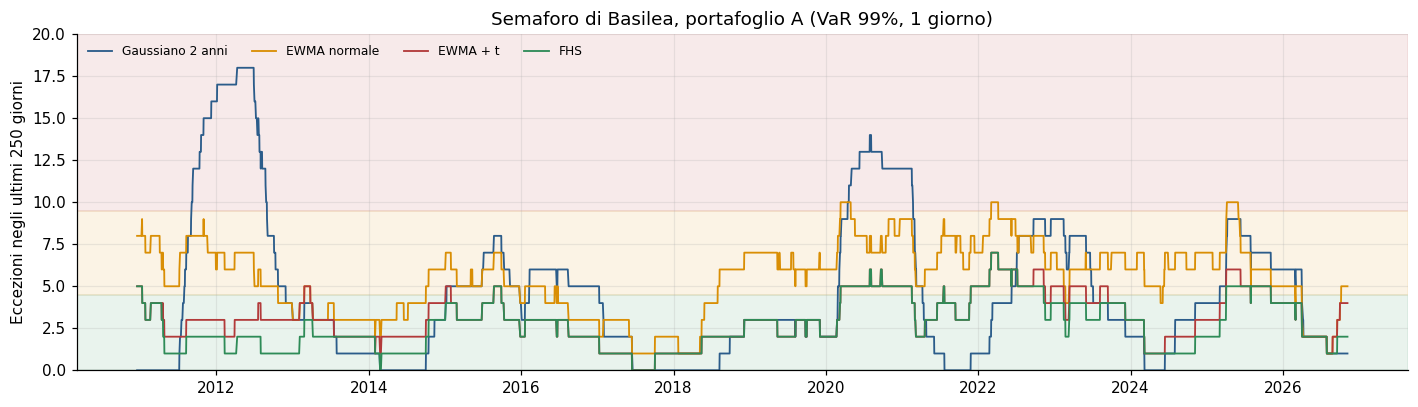

Quota del tempo in ciascuna zona del semaforo (portafoglio A):


,Verde (0-4),Gialla (5-9),Rossa (10+)
Gaussiano 2 anni,59%,29%,12%
EWMA normale,30%,68%,2%
EWMA normale ricalibrato,50%,50%,0%
EWMA + t,79%,21%,0%
FHS,83%,17%,0%


In [29]:
liv = 0.99 if 0.99 in LIVELLI else max(LIVELLI)
modelli_9 = [("Gaussiano 2 anni", "Gaussiano 2 anni", "#2B5C8A"), ("EWMA", "EWMA normale", "#D98E04"),
             ("EWMA + t", "EWMA + t", "#B23A3A"), ("FHS", "FHS", "#2E8B57")]
fig, ax = plt.subplots(figsize=(13, 3.8))
ymax = 12
for chiave, etichetta, col in modelli_9:
    c = serie_bt[("A — Concentrato", chiave, liv)]["eccezione"].rolling(250).sum()
    ax.plot(c.index, c, color=col, lw=1.2, label=etichetta); ymax = max(ymax, c.max() + 2)
ax.axhspan(0, 4.5, color="#2E8B57", alpha=0.10); ax.axhspan(4.5, 9.5, color="#D98E04", alpha=0.10)
ax.axhspan(9.5, ymax, color="#B23A3A", alpha=0.10); ax.set_ylim(0, ymax)
ax.set_ylabel("Eccezioni negli ultimi 250 giorni")
ax.set_title(f"Semaforo di Basilea, portafoglio A (VaR {liv:.0%}, 1 giorno)")
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=4)
plt.tight_layout(); plt.show()

zone_9 = {}
for chiave in ["Gaussiano 2 anni", "EWMA", "EWMA normale ricalibrato", "EWMA + t", "FHS"]:
    c = serie_bt[("A — Concentrato", chiave, liv)]["eccezione"].rolling(250).sum().dropna()
    zone_9[{"EWMA": "EWMA normale"}.get(chiave, chiave)] = {
        "Verde (0-4)": (c <= 4).mean(), "Gialla (5-9)": ((c >= 5) & (c <= 9)).mean(), "Rossa (10+)": (c >= 10).mean()}
print("Quota del tempo in ciascuna zona del semaforo (portafoglio A):")
display(pd.DataFrame(zone_9).T.style.format("{:.0%}"))

### Come leggere i risultati

**1. L'asimmetria.** Una skewness negativa e più osservazioni nella coda sinistra che nella destra confermano che le perdite estreme sono più frequenti dei guadagni estremi. Se la coda sinistra supera anche il numero atteso con la t, la t simmetrica sottostima il rischio di perdita.

**2. La scomposizione.** Nella tabella colorata, il percorso dall'alto verso il basso mostra quale ingrediente fa la differenza:
- se l'**EWMA normale ricalibrato** è già vicino all'EWMA + t, gran parte del miglioramento dello Step 8 veniva dalla scala, non dalle code;
- se invece resta lontano, il miglioramento è dovuto davvero allo **spessore delle code**;
- se la **FHS** migliora ulteriormente al 99%, l'asimmetria conta.

**3. La sintesi.** Conta soprattutto la prima colonna: a 1 giorno i test hanno la potenza per distinguere i modelli. A 21 giorni quasi tutti i modelli vengono "promossi" per mancanza di potenza, quindi quella colonna dice poco.

**4. Cosa rimane.** Se anche la FHS mostra ancora grappoli al 95%, il difetto non è nella distribuzione ma nella **dinamica della volatilità**: l'EWMA reagisce in modo simmetrico e con ritardo. Il passo successivo sarebbe un modello GJR-GARCH, in cui la volatilità sale di più dopo una perdita che dopo un guadagno.

**Un limite della FHS.** Il quantile empirico al 99% si stima con poche osservazioni nella coda (circa 1 residuo su 100) ed è vincolato agli eventi già osservati: la FHS non può prevedere una perdita più estrema della peggiore già vista. La t, al contrario, estrapola oltre i dati.

## Salvataggio dei risultati

Il blocco seguente salva le tabelle in file CSV. In Colab li trovi nel pannello **File** (icona a forma di cartella sulla sinistra) e puoi scaricarli con il tasto destro → *Scarica*.

**Nota:** i file salvati in Colab vengono cancellati quando chiudi la sessione. Scaricali, oppure salva una copia del notebook nel tuo Google Drive (*File → Salva una copia in Drive*).

In [30]:
prezzi.to_csv("prezzi.csv")
parametri.to_csv("parametri.csv")
pd.DataFrame(corr, index=NOMI, columns=NOMI).to_csv("correlazioni.csv")
risultati.to_csv("var_es.csv")
pd.DataFrame(confronto).to_csv("verifiche.csv", index=False)
sensibilita.to_csv("sensibilita_correlazione.csv")
crisi.to_csv("crisi_storiche.csv")
stress.to_csv("stress_correlazione_volatilita.csv")
confronto_p.to_csv("confronto_portafogli.csv")
stress_p.to_csv("stress_portafogli.csv")
backtest_tab.to_csv("backtest.csv")
per_anno.to_csv("eccezioni_per_anno.csv")
backtest_finale.to_csv("backtest_tre_modelli.csv")
anni_fin.to_csv("eccezioni_per_anno_tre_modelli.csv")
mc_t.to_csv("var_es_normale_vs_t.csv")
backtest_9.to_csv("backtest_cinque_modelli.csv")
scala_modelli.to_csv("scomposizione_miglioramento.csv")
anomalie.to_csv("anomalie.csv", index=False)
print("File salvati: prezzi, parametri, correlazioni, var_es, verifiche, anomalie, sensibilita_correlazione, crisi_storiche, stress_correlazione_volatilita, confronto_portafogli, stress_portafogli, backtest, eccezioni_per_anno, backtest_tre_modelli, eccezioni_per_anno_tre_modelli, var_es_normale_vs_t, backtest_cinque_modelli, scomposizione_miglioramento (.csv)")

File salvati: prezzi, parametri, correlazioni, var_es, verifiche, anomalie, sensibilita_correlazione, crisi_storiche, stress_correlazione_volatilita, confronto_portafogli, stress_portafogli, backtest, eccezioni_per_anno, backtest_tre_modelli, eccezioni_per_anno_tre_modelli, var_es_normale_vs_t, backtest_cinque_modelli, scomposizione_miglioramento (.csv)


## Prossimi passi

1. **GJR-GARCH:** una volatilità che reagisce più alle perdite che ai guadagni, per eliminare i grappoli residui di eccezioni al 95%.
2. **t asimmetrica** (skewed t di Hansen): un parametro in più per l'asimmetria, mantenendo la capacità della t di estrapolare oltre gli eventi osservati.
3. **Backtest dell'Expected Shortfall** (test di Acerbi e Székely): verificare non solo *quante* volte si supera il VaR, ma *di quanto*.
4. **Giorni di annuncio FOMC:** confrontare correlazioni, residui ed eccezioni nei giorni di annuncio della Fed e negli altri giorni.
5. **Scomposizione del rischio:** VaR per componente (contributo di ciascun titolo).

**Limiti:** il Monte Carlo degli Step 3–6 usa rendimenti normali con parametri costanti (lo Step 8 ne misura le conseguenze); la t multivariata usa un unico parametro ν per tutti i titoli; i titoli sono scelti fra quelli quotati oggi (distorsione da sopravvivenza); le finestre di crisi sono brevi e le relative stime rumorose.